# Notebook 3 — Conditional Diffusion Reconstruction and Evaluation: Workflow Guide

## Purpose
Train and evaluate a conditional diffusion model to reconstruct damaged regions of pharmacy-label images while preserving visible content.

## Flow
1. Import dependencies, set configuration/runtime limits, and locate the dataset.
2. Build source-image groups and create leakage-aware train/validation/test subsets; prepare damage-centred crops where configured.
3. Run damage diagnostics and inspect training/validation samples.
4. Define the time-conditioned U-Net, diffusion process, noise schedule, prediction target, and DDIM sampler.
5. Define optional classical colour-harmonisation methods, reconstruction metrics, and baseline methods.
6. Train using the configured time budget, mixed precision, and EMA where enabled.
7. Plot training history and load the selected EMA weights.
8. Select the colour-harmonisation option using validation data, then evaluate on the held-out test set.
9. Compare baselines and model outputs, visualize representative reconstructions, and run the efficiency benchmark.
10. Save or display the final figures and evaluation summary.

## Before running
Confirm that the dataset root contains the expected `clean`, `damaged`, and `masks` folders. Review image size, batch size, time budget, checkpoint paths, runtime settings, and output paths before a long run.

## Output
Depending on the cells executed and configured paths, outputs include checkpoints/history, quantitative metrics, reconstruction comparisons, and visualization files.

## Evaluation note
Use validation data for model or post-processing choices. Report test results from the held-out test evaluation and describe accurately which cells were run.


# Drug-label reconstruction with a conditional diffusion model (v2)

**What changed from v1**

| Area | v1 | v2 |
|---|---|---|
| Conditioning | damaged image with the mask region **zeroed** (pure inpainting) | full damaged image + mask, so faint text under stains/fading is still visible to the model |
| Network | 4.5M-param U-Net, time added only at the bottleneck | 22M-param U-Net, sinusoidal time embedding in **every** residual block (FiLM), self-attention at low resolution, zero-init residuals |
| Diffusion | linear β, ε-prediction, 200 steps | cosine schedule, **v-prediction**, 1000 train steps, min-SNR weighting, deterministic DDIM sampling (25 steps) |
| Losses | ε-MSE + masked ε-MSE + masked L1 | weighted v-MSE + masked x0 L1 + **low-frequency colour loss** + **edge (Sobel) loss** for sharp text |
| Training | full 416×416 images, batch 4, fp32, no workers | 256×256 crops centred on damage, AMP fp16, multi-worker loading, EMA weights, multi-GPU if available, automatic batch reduction on out-of-memory |
| Time | fixed 20 epochs (~10.4 h) | **time-budgeted**: stops at `TRAIN_HOURS`, cosine LR follows the time budget, resumable checkpoints |
| Colour seams | none | CV post-processing: **offset-field colour correction**, LAB statistics transfer, Poisson (gradient-domain) blending and their combination, selected on the validation set |
| Evaluation | PSNR/SSIM, ε-noise in metrics | baselines (damaged input, OpenCV Telea inpainting), masked PSNR/SSIM, pixel accuracy, **colour error ΔE2000**, optional OCR character error rate, fixed seeds |

**How to run on Kaggle**
1. Attach the same dataset (`clean/`, `damaged/`, `masks/`).
2. Accelerator: **GPU T4 x2** (uses both via DataParallel) or **P100**/**T4 x1**.
3. Click **Save Version → Save & Run All (Commit)**. Training stops itself after `TRAIN_HOURS` (default 8.5 h) and evaluation finishes well inside Kaggle's 12-hour limit. A global guard also trims evaluation if time runs short.
4. Results land in `/kaggle/working` (checkpoints, metrics CSVs, figures).

The leakage-free split uses exactly the same grouping, seed and ratios as v1, so test numbers are directly comparable.

In [7]:
# Cell 1: imports, global configuration and time guard
import os, math, time, json, random, shutil, subprocess, warnings, copy
from pathlib import Path

import numpy as np
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
import matplotlib
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity
from skimage.color import rgb2lab, deltaE_ciede2000

warnings.filterwarnings("ignore")
cv2.setNumThreads(0)
NOTEBOOK_START = time.time()

# Leave QUICK_TEST False on Kaggle. It only exists to smoke-test the notebook on a tiny dataset.
QUICK_TEST = os.environ.get("QUICK_TEST", "0") == "1"

CFG = dict(
    image_size=416,            # labels are resized to this (dataset416 is already 416)
    crop_size=256,             # training crop; inference runs on the full image
    batch_size=16,             # total batch (split across GPUs if more than one)
    base_channels=64,
    channel_mults=(1, 2, 3, 4),
    num_res_blocks=2,
    attn_levels=(3,),          # self-attention only at the lowest resolution (52x52 at inference)
    dropout=0.1,
    use_damaged_pixels=True,   # condition on the full damaged image instead of zeroing the mask region
    timesteps=1000,
    min_snr_gamma=5.0,
    mask_loss_weight=8.0,      # extra weight on damaged pixels in the v-loss
    lambda_x0_l1=1.0,
    lambda_colour=1.0,
    lambda_edge=0.5,
    lr=2e-4,
    weight_decay=1e-4,
    warmup_steps=1000,
    ema_decay=0.999,
    grad_clip=1.0,
    TRAIN_HOURS=8.5,           # total training time; evaluation needs ~1.5-2 h more on a T4
    NOTEBOOK_HOURS_LIMIT=11.6, # hard guard for the whole notebook (Kaggle limit is 12 h)
    ddim_steps=25,             # DDIM steps for evaluation (deterministic, v-pred + cosine works well at 25)
    val_psnr_images=32,        # fixed validation subset scored with real sampling after each epoch
    val_psnr_steps=10,
    val_loss_images=256,
    harmonizer_select_images=300,
    eval_max_test_images=None, # None = full test set
    eval_batch_size=16,
    ocr_eval_images=200,
    run_ocr_eval=True,
    resume_checkpoint=None,    # e.g. "/kaggle/input/<prev-output>/last_checkpoint.pth"
    seed=42,
    num_workers=min(4, os.cpu_count() or 2),
)
if QUICK_TEST:
    CFG.update(image_size=96, crop_size=64, batch_size=4, base_channels=32, channel_mults=(1, 2, 2, 2),
               num_res_blocks=1, TRAIN_HOURS=0.01, ddim_steps=4, val_psnr_steps=3, val_psnr_images=4, val_loss_images=8,
               harmonizer_select_images=6, eval_max_test_images=10, eval_batch_size=4, ocr_eval_images=4,
               warmup_steps=5, num_workers=0, run_ocr_eval=False)

OUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("./outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(CFG["seed"])

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_GPUS = torch.cuda.device_count()
USE_AMP = device.type == "cuda"
torch.backends.cudnn.benchmark = True

def hours_used():
    return (time.time() - NOTEBOOK_START) / 3600.0

def hours_left():
    return CFG["NOTEBOOK_HOURS_LIMIT"] - hours_used()

print(f"Device: {device} | GPUs: {NUM_GPUS} | AMP: {USE_AMP} | outputs -> {OUT_DIR}")
if NUM_GPUS:
    for i in range(NUM_GPUS):
        print(f"  GPU {i}: {torch.cuda.get_device_name(i)}")

Device: cuda | GPUs: 2 | AMP: True | outputs -> /kaggle/working
  GPU 0: Tesla T4
  GPU 1: Tesla T4


In [8]:
# Cell 2: locate the dataset (folder containing clean/, damaged/, masks/)
def find_data_root():
    if os.environ.get("DATA_ROOT"):
        return Path(os.environ["DATA_ROOT"])
    input_root = Path("/kaggle/input")
    for p in sorted(input_root.rglob("*")):
        if p.is_dir() and all((p / f).is_dir() for f in ["clean", "damaged", "masks"]):
            return p
    raise FileNotFoundError("No folder with clean/, damaged/, masks/ found under /kaggle/input. Attach the dataset.")

DATA_ROOT = find_data_root()
for sub in ["clean", "damaged", "masks"]:
    print(f"{sub:8s}: {len(os.listdir(DATA_ROOT / sub))} files")
print("Dataset root:", DATA_ROOT)

clean   : 6957 files
damaged : 20526 files
masks   : 20527 files
Dataset root: /kaggle/input/datasets/surajadhiikaree/dataset416


In [9]:
# Cell 3: leakage-free dataset (same grouping, seed and ratios as v1) with damage-centred crops
IMG_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".webp"}

def build_source_groups(root):
    clean_map, mask_map, groups = {}, {}, {}
    for f in os.listdir(root / "clean"):
        if not f.startswith(".") and Path(f).suffix.lower() in IMG_EXTS:
            clean_map[Path(f).stem.split("_")[0]] = f
    for f in os.listdir(root / "masks"):
        if not f.startswith(".") and Path(f).suffix.lower() in IMG_EXTS:
            mask_map[Path(f).stem] = f
    for f in os.listdir(root / "damaged"):
        if f.startswith(".") or Path(f).suffix.lower() not in IMG_EXTS:
            continue
        stem = Path(f).stem
        sid = stem.split("_")[0]
        if sid in clean_map and stem in mask_map:
            groups.setdefault(sid, []).append({"damaged": f, "clean": clean_map[sid], "mask": mask_map[stem]})
    return groups

def split_sources(groups, train_ratio=0.7, val_ratio=0.15, seed=42):
    sources = sorted(groups.keys())
    gen = torch.Generator().manual_seed(seed)
    idx = torch.randperm(len(sources), generator=gen).tolist()
    n_tr, n_va = int(len(sources) * train_ratio), int(len(sources) * val_ratio)
    tr = {sources[i] for i in idx[:n_tr]}
    va = {sources[i] for i in idx[n_tr:n_tr + n_va]}
    te = {sources[i] for i in idx[n_tr + n_va:]}
    assert tr.isdisjoint(va) and tr.isdisjoint(te) and va.isdisjoint(te), "Source leakage between splits!"
    return tr, va, te

def read_rgb(path, size):
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img is None:
        raise IOError(f"Could not read {path}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    if img.shape[0] != size or img.shape[1] != size:
        img = cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)
    return img.astype(np.float32) / 255.0

def read_mask(path, size):
    m = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if m is None:
        raise IOError(f"Could not read {path}")
    if m.shape[0] != size or m.shape[1] != size:
        m = cv2.resize(m, (size, size), interpolation=cv2.INTER_NEAREST)
    return (m > 127).astype(np.float32)

class PharmacyLabelDataset(Dataset):
    # Returns (clean, damaged, mask) in [-1, 1] / {0, 1}. Train mode returns damage-centred random crops.
    def __init__(self, root, samples, image_size, crop_size=None, train=False):
        self.root, self.samples = Path(root), samples
        self.image_size, self.crop_size, self.train = image_size, crop_size, train

    def __len__(self):
        return len(self.samples)

    def _crop_window(self, mask):
        s, c = self.image_size, self.crop_size
        if c is None or c >= s:
            return 0, 0
        ys, xs = np.nonzero(mask)
        if len(ys) > 0 and random.random() < 0.85:
            k = random.randrange(len(ys))
            cy = ys[k] + random.randint(-c // 4, c // 4)
            cx = xs[k] + random.randint(-c // 4, c // 4)
            y0, x0 = int(np.clip(cy - c // 2, 0, s - c)), int(np.clip(cx - c // 2, 0, s - c))
        else:
            y0, x0 = random.randint(0, s - c), random.randint(0, s - c)
        return y0, x0

    def __getitem__(self, i):
        it = self.samples[i]
        clean = read_rgb(self.root / "clean" / it["clean"], self.image_size)
        damaged = read_rgb(self.root / "damaged" / it["damaged"], self.image_size)
        mask = read_mask(self.root / "masks" / it["mask"], self.image_size)
        if self.train and self.crop_size:
            y0, x0 = self._crop_window(mask)
            c = self.crop_size
            clean, damaged, mask = clean[y0:y0+c, x0:x0+c], damaged[y0:y0+c, x0:x0+c], mask[y0:y0+c, x0:x0+c]
        to_t = lambda a: torch.from_numpy(np.ascontiguousarray(a)).permute(2, 0, 1) * 2.0 - 1.0
        return to_t(clean), to_t(damaged), torch.from_numpy(np.ascontiguousarray(mask))[None]

groups = build_source_groups(DATA_ROOT)
train_src, val_src, test_src = split_sources(groups, seed=CFG["seed"])
flatten = lambda srcs: [s for sid in sorted(srcs) for s in groups[sid]]
train_samples, val_samples, test_samples = flatten(train_src), flatten(val_src), flatten(test_src)

train_ds = PharmacyLabelDataset(DATA_ROOT, train_samples, CFG["image_size"], CFG["crop_size"], train=True)
val_ds = PharmacyLabelDataset(DATA_ROOT, val_samples, CFG["image_size"])
test_ds = PharmacyLabelDataset(DATA_ROOT, test_samples, CFG["image_size"])
print(f"Sources -> train {len(train_src)} | val {len(val_src)} | test {len(test_src)}")
print(f"Samples -> train {len(train_ds)} | val {len(val_ds)} | test {len(test_ds)}")

# Save the split manifest for the report
import csv
with open(OUT_DIR / "dataset_split_v2.csv", "w", newline="") as f:
    w = csv.writer(f); w.writerow(["source_id", "clean_file", "damaged_file", "mask_file", "split"])
    for name, ss in [("train", train_samples), ("val", val_samples), ("test", test_samples)]:
        for s in ss:
            w.writerow([s["damaged"].split("_")[0], s["clean"], s["damaged"], s["mask"], name])

Sources -> train 4869 | val 1043 | test 1045
Samples -> train 14362 | val 3088 | test 3073


In [10]:
# Cell 4: damage diagnostics - is the original text still partly visible under the damage?
rng = np.random.default_rng(0)
probe = rng.choice(len(val_ds), size=min(200, len(val_ds)), replace=False)
inside_err, outside_err, inside_corr, mask_frac = [], [], [], []
for i in probe:
    c, d, m = val_ds[int(i)]
    c, d, m = (c + 1) / 2, (d + 1) / 2, m[0].bool()
    mask_frac.append(m.float().mean().item())
    if m.sum() > 50:
        ci, di = c[:, m].flatten(), d[:, m].flatten()
        inside_err.append((ci - di).abs().mean().item())
        inside_corr.append(np.corrcoef(ci.numpy(), di.numpy())[0, 1])
    if (~m).sum() > 50:
        outside_err.append((c[:, ~m] - d[:, ~m]).abs().mean().item())

print(f"Mean damaged area fraction            : {np.mean(mask_frac):.3f}")
print(f"Mean |damaged-clean| outside the mask : {np.mean(outside_err):.4f}  (should be ~0)")
print(f"Mean |damaged-clean| inside the mask  : {np.mean(inside_err):.4f}")
print(f"Correlation damaged vs clean in mask  : {np.nanmean(inside_corr):.3f}")
if np.nanmean(inside_corr) > 0.3:
    print("-> Damaged pixels still carry information about the original. use_damaged_pixels=True should help a lot.")
else:
    print("-> Damaged pixels carry little information (mostly erased). The task is closer to pure inpainting.")

Mean damaged area fraction            : 0.069
Mean |damaged-clean| outside the mask : 0.0001  (should be ~0)
Mean |damaged-clean| inside the mask  : 0.0777
Correlation damaged vs clean in mask  : 0.634
-> Damaged pixels still carry information about the original. use_damaged_pixels=True should help a lot.


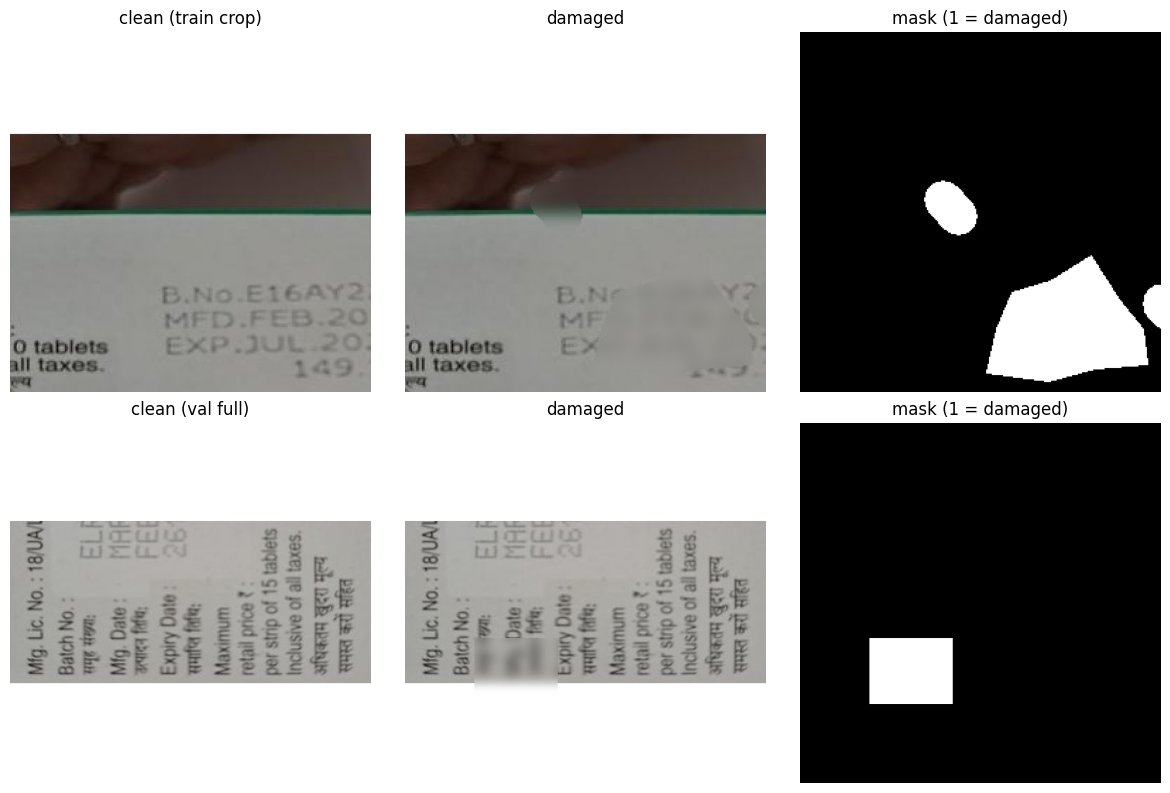

In [11]:
# Cell 5: visual check of a training crop and a full validation sample
to_img = lambda t: ((t.permute(1, 2, 0).cpu().float() + 1) / 2).clamp(0, 1).numpy()
c_tr, d_tr, m_tr = train_ds[0]
c_va, d_va, m_va = val_ds[0]
fig, ax = plt.subplots(2, 3, figsize=(12, 8))
for row, (c, d, m, name) in enumerate([(c_tr, d_tr, m_tr, "train crop"), (c_va, d_va, m_va, "val full")]):
    ax[row, 0].imshow(to_img(c)); ax[row, 0].set_title(f"clean ({name})")
    ax[row, 1].imshow(to_img(d)); ax[row, 1].set_title("damaged")
    ax[row, 2].imshow(m[0], cmap="gray"); ax[row, 2].set_title("mask (1 = damaged)")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(OUT_DIR / "data_check.png", dpi=110); plt.show()

In [12]:
# Cell 6: U-Net with per-block time conditioning and low-resolution self-attention
def timestep_embedding(t, dim, max_period=10000):
    half = dim // 2
    freqs = torch.exp(-math.log(max_period) * torch.arange(half, device=t.device, dtype=torch.float32) / half)
    args = t.float()[:, None] * freqs[None]
    return torch.cat([torch.cos(args), torch.sin(args)], dim=-1)

def norm(ch):
    return nn.GroupNorm(32 if ch % 32 == 0 else 8, ch)

def zero_module(m):
    for p in m.parameters():
        nn.init.zeros_(p)
    return m

class ResBlock(nn.Module):
    def __init__(self, cin, cout, tdim, dropout):
        super().__init__()
        self.n1, self.c1 = norm(cin), nn.Conv2d(cin, cout, 3, padding=1)
        self.t = nn.Linear(tdim, cout * 2)
        self.n2, self.drop = norm(cout), nn.Dropout(dropout)
        self.c2 = zero_module(nn.Conv2d(cout, cout, 3, padding=1))
        self.skip = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()

    def forward(self, x, temb):
        h = self.c1(F.silu(self.n1(x)))
        scale, shift = self.t(F.silu(temb))[:, :, None, None].chunk(2, dim=1)
        h = self.n2(h) * (1 + scale) + shift
        h = self.c2(self.drop(F.silu(h)))
        return h + self.skip(x)

class AttnBlock(nn.Module):
    def __init__(self, ch, heads=4):
        super().__init__()
        self.heads, self.n = heads, norm(ch)
        self.qkv = nn.Conv2d(ch, ch * 3, 1)
        self.proj = zero_module(nn.Conv2d(ch, ch, 1))

    def forward(self, x):
        B, C, H, W = x.shape
        q, k, v = self.qkv(self.n(x)).reshape(B, 3, self.heads, C // self.heads, H * W).unbind(1)
        q, k, v = (t.transpose(-1, -2) for t in (q, k, v))
        o = F.scaled_dot_product_attention(q, k, v)
        return x + self.proj(o.transpose(-1, -2).reshape(B, C, H, W))

class Downsample(nn.Module):
    def __init__(self, ch):
        super().__init__(); self.conv = nn.Conv2d(ch, ch, 3, stride=2, padding=1)
    def forward(self, x):
        return self.conv(x)

class Upsample(nn.Module):
    def __init__(self, ch):
        super().__init__(); self.conv = nn.Conv2d(ch, ch, 3, padding=1)
    def forward(self, x):
        return self.conv(F.interpolate(x, scale_factor=2, mode="nearest"))

class RestorationUNet(nn.Module):
    def __init__(self, in_ch=7, out_ch=3, base=64, mults=(1, 2, 3, 4), num_res=2, attn_levels=(3,), dropout=0.1):
        super().__init__()
        self.base, tdim = base, base * 4
        self.temb = nn.Sequential(nn.Linear(base, tdim), nn.SiLU(), nn.Linear(tdim, tdim))
        self.conv_in = nn.Conv2d(in_ch, base, 3, padding=1)
        self.down, chans, ch = nn.ModuleList(), [base], base
        for lvl, m in enumerate(mults):
            for _ in range(num_res):
                blk = nn.ModuleList([ResBlock(ch, base * m, tdim, dropout)]); ch = base * m
                if lvl in attn_levels:
                    blk.append(AttnBlock(ch))
                self.down.append(blk); chans.append(ch)
            if lvl != len(mults) - 1:
                self.down.append(nn.ModuleList([Downsample(ch)])); chans.append(ch)
        self.mid = nn.ModuleList([ResBlock(ch, ch, tdim, dropout), AttnBlock(ch), ResBlock(ch, ch, tdim, dropout)])
        self.up = nn.ModuleList()
        for lvl, m in reversed(list(enumerate(mults))):
            for i in range(num_res + 1):
                blk = nn.ModuleList([ResBlock(ch + chans.pop(), base * m, tdim, dropout)]); ch = base * m
                if lvl in attn_levels:
                    blk.append(AttnBlock(ch))
                if lvl != 0 and i == num_res:
                    blk.append(Upsample(ch))
                self.up.append(blk)
        self.out = nn.Sequential(norm(ch), nn.SiLU(), zero_module(nn.Conv2d(ch, out_ch, 3, padding=1)))
        self.depth = len(mults) - 1

    @staticmethod
    def _run(blk, h, temb):
        for layer in blk:
            h = layer(h, temb) if isinstance(layer, ResBlock) else layer(h)
        return h

    def forward(self, x, t):
        # pad so H and W are divisible by 2**depth, crop back at the end
        H, W = x.shape[-2:]
        f = 2 ** self.depth
        ph, pw = (f - H % f) % f, (f - W % f) % f
        if ph or pw:
            x = F.pad(x, (0, pw, 0, ph), mode="reflect")
        temb = self.temb(timestep_embedding(t, self.base))
        h = self.conv_in(x); hs = [h]
        for blk in self.down:
            h = self._run(blk, h, temb); hs.append(h)
        h = self._run(self.mid, h, temb)
        for blk in self.up:
            h = self._run(blk, torch.cat([h, hs.pop()], dim=1), temb)
        return self.out(h)[..., :H, :W]

model = RestorationUNet(in_ch=7, base=CFG["base_channels"], mults=CFG["channel_mults"],
                        num_res=CFG["num_res_blocks"], attn_levels=CFG["attn_levels"],
                        dropout=CFG["dropout"]).to(device)
total_params = sum(p.numel() for p in model.parameters())
print(f"RestorationUNet parameters: {total_params/1e6:.2f}M")

RestorationUNet parameters: 22.29M


In [13]:
# Cell 7: cosine-schedule v-prediction diffusion, losses and deterministic DDIM sampler
class Diffusion:
    def __init__(self, T=1000, s=0.008):
        self.T = T
        x = torch.linspace(0, T, T + 1, dtype=torch.float64)
        ac = torch.cos(((x / T) + s) / (1 + s) * math.pi / 2) ** 2
        ac = ac / ac[0]
        betas = (1 - ac[1:] / ac[:-1]).clamp(max=0.999)
        self.alpha_bar = torch.cumprod(1 - betas, 0).float().to(device)

    def coef(self, t):
        a = self.alpha_bar[t][:, None, None, None]
        return a.sqrt(), (1 - a).sqrt()

diffusion = Diffusion(CFG["timesteps"])

def make_condition(damaged, mask):
    cond = damaged if CFG["use_damaged_pixels"] else damaged * (1 - mask)
    return torch.cat([cond, mask], dim=1)

SOBEL_X = torch.tensor([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=torch.float32).view(1, 1, 3, 3)

def sobel(img):
    k = SOBEL_X.to(img.device, img.dtype)
    C = img.shape[1]
    gx = F.conv2d(img, k.repeat(C, 1, 1, 1), padding=1, groups=C)
    gy = F.conv2d(img, k.transpose(-1, -2).repeat(C, 1, 1, 1), padding=1, groups=C)
    return gx, gy

def diffusion_loss(net, clean, damaged, mask, t=None, noise=None):
    B = clean.shape[0]
    if t is None:
        t = torch.randint(0, diffusion.T, (B,), device=clean.device)
    if noise is None:
        noise = torch.randn_like(clean)
    sa, s1a = diffusion.coef(t)
    x_t = sa * clean + s1a * noise
    v_target = sa * noise - s1a * clean
    with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
        v_pred = net(torch.cat([x_t, make_condition(damaged, mask)], dim=1), t)
    v_pred = v_pred.float()

    # min-SNR-gamma weighting (v-prediction form) and extra weight on damaged pixels
    snr = (sa / s1a).pow(2).view(B)
    w_t = torch.clamp(snr, max=CFG["min_snr_gamma"]) / (snr + 1)
    w_px = 1.0 + CFG["mask_loss_weight"] * mask
    w_px = w_px / w_px.mean(dim=(1, 2, 3), keepdim=True)
    loss_v = ((v_pred - v_target).pow(2) * w_px).mean(dim=(1, 2, 3))
    loss_v = (w_t * loss_v).mean()

    # auxiliary losses on the predicted clean image, trusted more at low noise levels
    x0 = (sa * x_t - s1a * v_pred).clamp(-1, 1)
    w_aux = (sa.view(B) ** 2)
    m3 = mask.expand_as(clean)
    area = m3.sum(dim=(1, 2, 3)) + 1.0
    l1 = ((x0 - clean).abs() * m3).sum(dim=(1, 2, 3)) / area

    # low-frequency colour loss on the damaged region plus a band around it (fixes colour casts)
    band = F.max_pool2d(mask, 9, stride=1, padding=4).expand_as(clean)
    lf = lambda z: F.avg_pool2d(z, 9, stride=1, padding=4, count_include_pad=False)
    colour = ((lf(x0) - lf(clean)).abs() * band).sum(dim=(1, 2, 3)) / (band.sum(dim=(1, 2, 3)) + 1.0)

    gx_p, gy_p = sobel(x0); gx_c, gy_c = sobel(clean)
    edge = (((gx_p - gx_c).abs() + (gy_p - gy_c).abs()) * m3).sum(dim=(1, 2, 3)) / area

    aux = CFG["lambda_x0_l1"] * l1 + CFG["lambda_colour"] * colour + CFG["lambda_edge"] * edge
    loss = loss_v + (w_aux * aux).mean()
    return loss, {"v": loss_v.item(), "l1": l1.mean().item(), "colour": colour.mean().item(), "edge": edge.mean().item()}

@torch.no_grad()
def ddim_sample(net, damaged, mask, steps=50, seed=0, composite=True):
    # Deterministic DDIM (eta = 0) from fixed-seed noise. Returns images in [0, 1] and the raw full prediction.
    net.eval()
    B = damaged.shape[0]
    gen = torch.Generator(device=damaged.device).manual_seed(seed)
    x = torch.randn(damaged.shape, generator=gen, device=damaged.device)
    cond = make_condition(damaged, mask)
    ts = torch.linspace(diffusion.T - 1, 0, steps, device=damaged.device).round().long()
    for i, t in enumerate(ts):
        tb = torch.full((B,), int(t), device=damaged.device, dtype=torch.long)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            v = net(torch.cat([x, cond], dim=1), tb).float()
        a = diffusion.alpha_bar[t]
        x0 = (a.sqrt() * x - (1 - a).sqrt() * v).clamp(-1, 1)
        eps = (x - a.sqrt() * x0) / (1 - a).sqrt()
        if i < len(ts) - 1:
            a_next = diffusion.alpha_bar[ts[i + 1]]
            x = a_next.sqrt() * x0 + (1 - a_next).sqrt() * eps
        else:
            x = x0
    raw = (x.clamp(-1, 1) + 1) / 2
    known = (damaged + 1) / 2
    out = raw * mask + known * (1 - mask) if composite else raw
    return out, raw

In [14]:
# Cell 8: classical CV colour harmonisation for the reconstructed region
# All functions take float images in [0,1] (H,W,3) and a boolean mask (H,W). `pred` is the model's full-image
# prediction; `known` is the damaged image, whose pixels outside the mask are trusted.

def _ring(mask, width):
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * width + 1, 2 * width + 1))
    dil = cv2.dilate(mask.astype(np.uint8), k) > 0
    return dil & ~mask

def composite(pred, known, mask):
    m = mask[..., None].astype(np.float32)
    return pred * m + known * (1 - m)

def feather_blend(pred, known, mask, radius=4):
    # Soft alpha edge so the seam fades over a few pixels instead of a hard step.
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * radius + 1, 2 * radius + 1))
    dil = cv2.dilate(mask.astype(np.uint8), k).astype(np.float32)
    alpha = cv2.GaussianBlur(dil, (0, 0), radius / 2.0)
    alpha = np.maximum(alpha, mask.astype(np.float32))[..., None]
    return pred * alpha + known * (1 - alpha)

def offset_field_correct(pred, known, mask, ring_width=12, sigma=18.0, fallback_k=0.02):
    # Estimate a smooth colour offset (known - pred) on a ring of trusted pixels around each damaged region,
    # spread it into the hole with normalised Gaussian convolution, and add it to the prediction.
    # Only low frequencies change, so text strokes are untouched while colour casts are removed.
    ring = _ring(mask, ring_width)
    if ring.sum() < 20:
        return composite(pred, known, mask)
    r = ring.astype(np.float32)
    diff = (known - pred) * r[..., None]
    num = cv2.GaussianBlur(diff, (0, 0), sigma)
    den = cv2.GaussianBlur(r, (0, 0), sigma)[..., None]
    global_off = diff.sum(axis=(0, 1)) / max(r.sum(), 1.0)
    offset = (num + fallback_k * global_off) / (den + fallback_k)
    corrected = np.clip(pred + offset, 0, 1)
    return composite(corrected, known, mask)

def lab_stats_transfer(pred, known, mask, ring_width=12):
    # Reinhard-style transfer in LAB: match mean/std of the prediction to the known pixels on the surrounding ring.
    ring = _ring(mask, ring_width)
    if ring.sum() < 20:
        return composite(pred, known, mask)
    lp, lk = rgb2lab(pred), rgb2lab(known)
    mu_p, sd_p = lp[ring].mean(0), lp[ring].std(0) + 1e-3
    mu_k, sd_k = lk[ring].mean(0), lk[ring].std(0) + 1e-3
    gain = np.clip(sd_k / sd_p, 0.5, 2.0)
    out = lp.copy()
    out[mask] = (lp[mask] - mu_p) * gain + mu_k
    from skimage.color import lab2rgb
    return composite(np.clip(lab2rgb(out), 0, 1), known, mask)

def poisson_blend(pred, known, mask, pad=16):
    # Gradient-domain (Poisson) blending with OpenCV seamlessClone: keeps the predicted gradients (text edges)
    # and solves for colours that agree with the known pixels on the boundary.
    if mask.sum() < 10:
        return composite(pred, known, mask)
    to8 = lambda a: (np.clip(a, 0, 1) * 255 + 0.5).astype(np.uint8)
    src = cv2.copyMakeBorder(to8(pred), pad, pad, pad, pad, cv2.BORDER_REFLECT)
    dst = cv2.copyMakeBorder(to8(known), pad, pad, pad, pad, cv2.BORDER_REFLECT)
    m = cv2.copyMakeBorder(mask.astype(np.uint8) * 255, pad, pad, pad, pad, cv2.BORDER_CONSTANT, value=0)
    m = cv2.dilate(m, np.ones((3, 3), np.uint8))
    x, y, w, h = cv2.boundingRect(m)
    center = (x + w // 2, y + h // 2)
    try:
        out = cv2.seamlessClone(src, dst, m, center, cv2.NORMAL_CLONE)
    except cv2.error:
        return composite(pred, known, mask)
    out = out[pad:-pad, pad:-pad].astype(np.float32) / 255.0
    return composite(out, known, mask)

def offset_then_feather(pred, known, mask):
    ring = _ring(mask, 12)
    if ring.sum() < 20:
        return feather_blend(pred, known, mask)
    r = ring.astype(np.float32)
    diff = (known - pred) * r[..., None]
    num = cv2.GaussianBlur(diff, (0, 0), 18.0)
    den = cv2.GaussianBlur(r, (0, 0), 18.0)[..., None]
    g = diff.sum(axis=(0, 1)) / max(r.sum(), 1.0)
    corrected = np.clip(pred + (num + 0.02 * g) / (den + 0.02), 0, 1)
    return feather_blend(corrected, known, mask)

def offset_then_poisson(pred, known, mask):
    ring = _ring(mask, 12)
    if ring.sum() < 20:
        return poisson_blend(pred, known, mask)
    r = ring.astype(np.float32)
    diff = (known - pred) * r[..., None]
    num = cv2.GaussianBlur(diff, (0, 0), 18.0)
    den = cv2.GaussianBlur(r, (0, 0), 18.0)[..., None]
    g = diff.sum(axis=(0, 1)) / max(r.sum(), 1.0)
    corrected = np.clip(pred + (num + 0.02 * g) / (den + 0.02), 0, 1)
    return poisson_blend(corrected, known, mask)

HARMONIZERS = {
    "raw_composite": composite,
    "offset_field": offset_field_correct,
    "lab_stats": lab_stats_transfer,
    "poisson": poisson_blend,
    "offset+poisson": offset_then_poisson,
}
print("Harmonizers:", list(HARMONIZERS))

Harmonizers: ['raw_composite', 'offset_field', 'lab_stats', 'poisson', 'offset+poisson']


In [15]:
# Cell 9: metrics (full / masked PSNR, SSIM, pixel accuracy, colour error dE2000) and baselines
def psnr(a, b):
    mse = float(np.mean((a - b) ** 2))
    return 100.0 if mse == 0 else 10 * math.log10(1.0 / mse)

def image_metrics(pred, clean, mask):
    m = mask.astype(bool)
    out = {"psnr": psnr(pred, clean),
           "ssim": structural_similarity(pred, clean, channel_axis=2, data_range=1.0),
           "pix_acc": float(np.mean(np.abs(pred - clean) < 0.15) * 100)}
    if m.sum() > 0:
        out["masked_psnr"] = psnr(pred[m], clean[m])
        out["masked_pix_acc"] = float(np.mean(np.abs(pred[m] - clean[m]) < 0.15) * 100)
        ys, xs = np.nonzero(m)
        y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
        if (y1 - y0) >= 7 and (x1 - x0) >= 7:
            out["masked_bbox_ssim"] = structural_similarity(pred[y0:y1, x0:x1], clean[y0:y1, x0:x1],
                                                            channel_axis=2, data_range=1.0)
        out["masked_deltaE"] = float(np.mean(deltaE_ciede2000(rgb2lab(pred)[m], rgb2lab(clean)[m])))
    return out

def telea_baseline(known, mask):
    img8 = (np.clip(known, 0, 1) * 255 + 0.5).astype(np.uint8)
    out = cv2.inpaint(img8, mask.astype(np.uint8) * 255, 3, cv2.INPAINT_TELEA)
    return out.astype(np.float32) / 255.0

def summarise(rows):
    keys = ["masked_psnr", "masked_bbox_ssim", "masked_pix_acc", "masked_deltaE", "psnr", "ssim", "pix_acc"]
    res = {}
    for k in keys:
        vals = [r[k] for r in rows if k in r and np.isfinite(r[k])]
        res[k] = (float(np.mean(vals)), float(np.std(vals))) if vals else (float("nan"), float("nan"))
    return res

to_np = lambda t: t.permute(1, 2, 0).cpu().float().numpy()

In [16]:
# Cell 10: training with AMP, EMA, damage-centred crops and a wall-clock budget
train_loader = DataLoader(train_ds, batch_size=CFG["batch_size"], shuffle=True, drop_last=True,
                          num_workers=CFG["num_workers"], pin_memory=(device.type == "cuda"),
                          persistent_workers=CFG["num_workers"] > 0)
val_loss_subset = Subset(val_ds, list(range(0, len(val_ds), max(1, len(val_ds) // CFG["val_loss_images"])))[:CFG["val_loss_images"]])
val_psnr_subset = Subset(val_ds, list(range(0, len(val_ds), max(1, len(val_ds) // CFG["val_psnr_images"])))[:CFG["val_psnr_images"]])
val_loss_loader = DataLoader(val_loss_subset, batch_size=CFG["eval_batch_size"], num_workers=CFG["num_workers"])
val_psnr_loader = DataLoader(val_psnr_subset, batch_size=CFG["eval_batch_size"], num_workers=CFG["num_workers"])

net = nn.DataParallel(model) if NUM_GPUS > 1 else model
ema = copy.deepcopy(model).eval()
for p in ema.parameters():
    p.requires_grad_(False)
optimizer = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"], betas=(0.9, 0.99))
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

state = {"step": 0, "epoch": 0, "train_seconds": 0.0, "best_val_masked_psnr": -1.0, "history": []}
if CFG["resume_checkpoint"] and Path(CFG["resume_checkpoint"]).exists():
    ck = torch.load(CFG["resume_checkpoint"], map_location=device, weights_only=False)
    model.load_state_dict(ck["model"]); ema.load_state_dict(ck["ema"])
    optimizer.load_state_dict(ck["optimizer"]); scaler.load_state_dict(ck["scaler"])
    state.update(ck["state"])
    print(f"Resumed from {CFG['resume_checkpoint']} at epoch {state['epoch']}, {state['train_seconds']/3600:.2f} h trained")

budget_s = CFG["TRAIN_HOURS"] * 3600

def probe_batch_size():
    # Try one forward/backward at the configured batch; halve on out-of-memory.
    bs = CFG["batch_size"]
    while device.type == "cuda" and bs >= 2:
        try:
            c = torch.randn(bs, 3, CFG["crop_size"], CFG["crop_size"], device=device)
            m = (torch.rand(bs, 1, CFG["crop_size"], CFG["crop_size"], device=device) > 0.8).float()
            loss, _ = diffusion_loss(net, c, c, m)
            scaler.scale(loss).backward(); optimizer.zero_grad(set_to_none=True)
            peak = torch.cuda.max_memory_allocated() / 2**30
            print(f"Batch size {bs} fits (peak {peak:.1f} GB on GPU 0)")
            return bs
        except torch.OutOfMemoryError:
            optimizer.zero_grad(set_to_none=True); torch.cuda.empty_cache()
            print(f"Batch size {bs} ran out of memory, halving")
            bs //= 2
    return CFG["batch_size"]

bs_ok = probe_batch_size()
if bs_ok != CFG["batch_size"]:
    CFG["batch_size"] = bs_ok
    train_loader = DataLoader(train_ds, batch_size=bs_ok, shuffle=True, drop_last=True,
                              num_workers=CFG["num_workers"], pin_memory=True,
                              persistent_workers=CFG["num_workers"] > 0)
torch.cuda.empty_cache() if device.type == "cuda" else None

def lr_at(step, progress):
    if step < CFG["warmup_steps"]:
        return CFG["lr"] * (step + 1) / CFG["warmup_steps"]
    return 1e-6 + 0.5 * (CFG["lr"] - 1e-6) * (1 + math.cos(math.pi * min(progress, 1.0)))

@torch.no_grad()
def ema_update(step):
    d = min(CFG["ema_decay"], (1 + step) / (10 + step))
    for pe, pm in zip(ema.parameters(), model.parameters()):
        pe.mul_(d).add_(pm.detach(), alpha=1 - d)
    for be, bm in zip(ema.buffers(), model.buffers()):
        be.copy_(bm)

@torch.no_grad()
def validation_loss(netw):
    netw.eval(); g = torch.Generator(device="cpu").manual_seed(123); tot, n = 0.0, 0
    for c, d, m in val_loss_loader:
        c, d, m = c.to(device), d.to(device), m.to(device)
        t = torch.randint(0, diffusion.T, (c.shape[0],), generator=g).to(device)
        noise = torch.randn(c.shape, generator=g).to(device)
        loss, _ = diffusion_loss(netw, c, d, m, t=t, noise=noise)
        tot += loss.item() * c.shape[0]; n += c.shape[0]
    return tot / max(n, 1)

@torch.no_grad()
def validation_masked_psnr(netw, steps):
    scores = []
    for c, d, m in val_psnr_loader:
        d, m = d.to(device), m.to(device)
        out, _ = ddim_sample(netw, d, m, steps=steps, seed=0)
        for i in range(c.shape[0]):
            mm = m[i, 0].cpu().numpy() > 0.5
            if mm.sum():
                scores.append(psnr(to_np(out[i])[mm], to_np((c[i] + 1) / 2)[mm]))
    return float(np.mean(scores)) if scores else float("nan")

def save_checkpoint(path):
    torch.save({"model": model.state_dict(), "ema": ema.state_dict(), "optimizer": optimizer.state_dict(),
                "scaler": scaler.state_dict(), "state": state, "cfg": CFG}, path)

print(f"Training for up to {CFG['TRAIN_HOURS']:.2f} h | {len(train_loader)} steps/epoch | batch {CFG['batch_size']}")
log_every = 200 if not QUICK_TEST else 1
session_start = time.time(); prior_seconds = state["train_seconds"]
stop = False
while not stop:
    model.train(); net.train()
    ep_loss, ep_n, t_ep = 0.0, 0, time.time()
    for c, d, m in train_loader:
        elapsed = prior_seconds + (time.time() - session_start)
        if elapsed >= budget_s or hours_left() < 1.6:
            stop = True; break
        c, d, m = c.to(device, non_blocking=True), d.to(device, non_blocking=True), m.to(device, non_blocking=True)
        for g_ in optimizer.param_groups:
            g_["lr"] = lr_at(state["step"], elapsed / budget_s)
        loss, parts = diffusion_loss(net, c, d, m)
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
        scaler.step(optimizer); scaler.update()
        ema_update(state["step"])
        state["step"] += 1; ep_loss += loss.item(); ep_n += 1
        if state["step"] % log_every == 0:
            print(f"  step {state['step']:6d} | loss {loss.item():.4f} | v {parts['v']:.4f} | l1 {parts['l1']:.4f} "
                  f"| colour {parts['colour']:.4f} | edge {parts['edge']:.4f} | lr {optimizer.param_groups[0]['lr']:.2e} "
                  f"| {elapsed/3600:.2f} h")
    if ep_n == 0:
        break
    state["epoch"] += 1
    state["train_seconds"] = prior_seconds + (time.time() - session_start)
    vloss = validation_loss(ema)
    vpsnr = validation_masked_psnr(ema, steps=CFG["val_psnr_steps"])
    state["history"].append({"epoch": state["epoch"], "step": state["step"], "train_loss": ep_loss / ep_n,
                             "val_loss": vloss, "val_masked_psnr": vpsnr, "hours": state["train_seconds"] / 3600,
                             "partial_epoch": stop})
    print(f"Epoch {state['epoch']:3d} | train {ep_loss/ep_n:.4f} | val loss {vloss:.4f} | val masked PSNR {vpsnr:.2f} dB "
          f"| epoch time {(time.time()-t_ep)/60:.1f} min | total {state['train_seconds']/3600:.2f} h")
    if vpsnr > state["best_val_masked_psnr"]:
        state["best_val_masked_psnr"] = vpsnr
        torch.save({"ema": ema.state_dict(), "cfg": CFG, "epoch": state["epoch"]}, OUT_DIR / "best_ema.pth")
        print(f"  -> new best EMA checkpoint (val masked PSNR {vpsnr:.2f} dB)")
    save_checkpoint(OUT_DIR / "last_checkpoint.pth")
    with open(OUT_DIR / "train_history.json", "w") as f:
        json.dump(state["history"], f, indent=1)

print(f"Training finished: {state['epoch']} epochs, {state['step']} steps, {state['train_seconds']/3600:.2f} h")

Batch size 16 fits (peak 13.2 GB on GPU 0)
Training for up to 8.50 h | 897 steps/epoch | batch 16
  step    200 | loss 0.5351 | v 0.1697 | l1 0.2174 | colour 0.0921 | edge 1.3037 | lr 4.00e-05 | 0.23 h
  step    400 | loss 0.2363 | v 0.0584 | l1 0.1286 | colour 0.0553 | edge 0.8336 | lr 8.00e-05 | 0.43 h
  step    600 | loss 0.1545 | v 0.0230 | l1 0.1063 | colour 0.0553 | edge 0.6476 | lr 1.20e-04 | 0.63 h
  step    800 | loss 0.1502 | v 0.0164 | l1 0.1110 | colour 0.0666 | edge 0.6175 | lr 1.60e-04 | 0.83 h
Epoch   1 | train 0.3563 | val loss 0.1291 | val masked PSNR 20.43 dB | epoch time 57.9 min | total 0.93 h
  -> new best EMA checkpoint (val masked PSNR 20.43 dB)
  step   1000 | loss 0.1626 | v 0.0109 | l1 0.0742 | colour 0.0350 | edge 0.4480 | lr 2.00e-04 | 1.07 h
  step   1200 | loss 0.1126 | v 0.0073 | l1 0.0820 | colour 0.0367 | edge 0.5175 | lr 1.89e-04 | 1.27 h
  step   1400 | loss 0.1280 | v 0.0079 | l1 0.0638 | colour 0.0259 | edge 0.4226 | lr 1.86e-04 | 1.47 h
  step   16

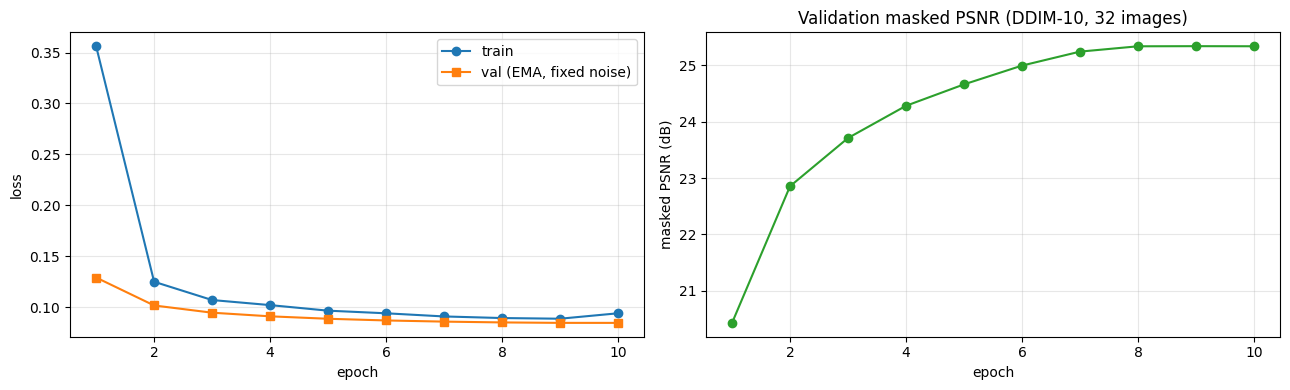

In [17]:
# Cell 11: training curves
hist = state["history"]
if hist:
    ep = [h["epoch"] for h in hist]
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].plot(ep, [h["train_loss"] for h in hist], "o-", label="train")
    ax[0].plot(ep, [h["val_loss"] for h in hist], "s-", label="val (EMA, fixed noise)")
    ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss"); ax[0].legend(); ax[0].grid(alpha=0.3)
    ax[1].plot(ep, [h["val_masked_psnr"] for h in hist], "o-", color="tab:green")
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("masked PSNR (dB)"); ax[1].set_title(f"Validation masked PSNR (DDIM-{CFG['val_psnr_steps']}, 32 images)")
    ax[1].grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(OUT_DIR / "training_curves.png", dpi=120); plt.show()

In [18]:
# Cell 12: load the best EMA weights for evaluation
best_path = OUT_DIR / "best_ema.pth"
if best_path.exists():
    ema.load_state_dict(torch.load(best_path, map_location=device, weights_only=False)["ema"])
    print("Loaded best EMA checkpoint from", best_path)
eval_net = (nn.DataParallel(ema) if NUM_GPUS > 1 else ema).eval()

Loaded best EMA checkpoint from /kaggle/working/best_ema.pth


In [19]:
# Cell 13 (FAST): choose the colour-harmonisation method on a small VALIDATION subset
import concurrent.futures as cf
from skimage.color import lab2rgb
cv2.setNumThreads(2)
N_SELECT = 64

def lab_stats_transfer(pred, known, mask, ring_width=12):
    ring = _ring(mask, ring_width)
    if ring.sum() < 20:
        return composite(pred, known, mask)
    lp_r, lk_r = rgb2lab(pred[ring][None])[0], rgb2lab(known[ring][None])[0]
    lp_m = rgb2lab(pred[mask][None])[0]
    mu_p, sd_p = lp_r.mean(0), lp_r.std(0) + 1e-3
    mu_k, sd_k = lk_r.mean(0), lk_r.std(0) + 1e-3
    new = (lp_m - mu_p) * np.clip(sd_k / sd_p, 0.5, 2.0) + mu_k
    out = known.copy()
    out[mask] = np.clip(lab2rgb(new[None])[0], 0, 1)
    return out
HARMONIZERS["lab_stats"] = lab_stats_transfer

def image_metrics(pred, clean, mask, full=True):
    m = mask.astype(bool)
    out = {}
    if full:
        out["psnr"] = psnr(pred, clean)
        out["ssim"] = structural_similarity(pred, clean, channel_axis=2, data_range=1.0)
        out["pix_acc"] = float(np.mean(np.abs(pred - clean) < 0.15) * 100)
    if m.sum() > 0:
        p, c = pred[m], clean[m]
        out["masked_psnr"] = psnr(p, c)
        out["masked_pix_acc"] = float(np.mean(np.abs(p - c) < 0.15) * 100)
        ys, xs = np.nonzero(m)
        y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
        if (y1 - y0) >= 7 and (x1 - x0) >= 7:
            out["masked_bbox_ssim"] = structural_similarity(pred[y0:y1, x0:x1], clean[y0:y1, x0:x1],
                                                            channel_axis=2, data_range=1.0)
        out["masked_deltaE"] = float(np.mean(deltaE_ciede2000(rgb2lab(p[None]), rgb2lab(c[None]))))
    return out

def _score_one(args):
    clean_i, known_i, pred_i, mm = args
    return {name: image_metrics(fn(pred_i, known_i, mm), clean_i, mm, full=False) for name, fn in HARMONIZERS.items()}

sel_idx = np.linspace(0, len(val_ds) - 1, min(N_SELECT, len(val_ds))).round().astype(int).tolist()
sel_loader = DataLoader(Subset(val_ds, sel_idx), batch_size=CFG["eval_batch_size"], num_workers=CFG["num_workers"])
sel_rows = {k: [] for k in HARMONIZERS}
pool = cf.ThreadPoolExecutor(max_workers=os.cpu_count() or 4)
t0, done = time.time(), 0
for c, d, m in sel_loader:
    _, raw = ddim_sample(eval_net, d.to(device), m.to(device), steps=CFG["ddim_steps"], seed=0)
    jobs = [(to_np((c[i] + 1) / 2), to_np((d[i] + 1) / 2), to_np(raw[i]), m[i, 0].numpy() > 0.5)
            for i in range(c.shape[0]) if (m[i, 0] > 0.5).any()]
    for res in pool.map(_score_one, jobs):
        for k, v in res.items():
            sel_rows[k].append(v)
    done += c.shape[0]
    print(f"  {done}/{len(sel_idx)} images | {time.time()-t0:.0f} s")
pool.shutdown()

print(f"\n{'harmoniser':16s} {'masked PSNR':>12s} {'masked dE':>10s} {'bbox SSIM':>10s}")
sel_summary = {k: summarise(v) for k, v in sel_rows.items() if v}
for k, s in sel_summary.items():
    print(f"{k:16s} {s['masked_psnr'][0]:12.2f} {s['masked_deltaE'][0]:10.2f} {s['masked_bbox_ssim'][0]:10.4f}")
best_h = max(sel_summary, key=lambda k: (round(sel_summary[k]["masked_psnr"][0], 1), -sel_summary[k]["masked_deltaE"][0]))
print(f"\nSelected harmoniser: {best_h}")


# Cell 13: choose the colour-harmonisation method on the VALIDATION set (no test peeking)
# sel_idx = list(range(0, len(val_ds), max(1, len(val_ds) // CFG["harmonizer_select_images"])))[:CFG["harmonizer_select_images"]]
# sel_loader = DataLoader(Subset(val_ds, sel_idx), batch_size=CFG["eval_batch_size"], num_workers=CFG["num_workers"])
# sel_rows = {k: [] for k in HARMONIZERS}
# for c, d, m in sel_loader:
#     if hours_left() < 1.0:
#         print("Time guard: stopping harmoniser selection early"); break
#     _, raw = ddim_sample(eval_net, d.to(device), m.to(device), steps=CFG["ddim_steps"], seed=0)
#     for i in range(c.shape[0]):
#         clean_i, known_i, pred_i = to_np((c[i] + 1) / 2), to_np((d[i] + 1) / 2), to_np(raw[i])
#         mm = m[i, 0].numpy() > 0.5
#         if not mm.any():
#             continue
#         for name, fn in HARMONIZERS.items():
#             sel_rows[name].append(image_metrics(fn(pred_i, known_i, mm), clean_i, mm))

# print(f"{'harmoniser':16s} {'masked PSNR':>12s} {'masked dE':>10s} {'bbox SSIM':>10s}")
# sel_summary = {k: summarise(v) for k, v in sel_rows.items() if v}
# for k, s in sel_summary.items():
#     print(f"{k:16s} {s['masked_psnr'][0]:12.2f} {s['masked_deltaE'][0]:10.2f} {s['masked_bbox_ssim'][0]:10.4f}")
# # rank by masked PSNR, break near-ties (<0.1 dB) by lower colour error 
# best_h = max(sel_summary, key=lambda k: (round(sel_summary[k]["masked_psnr"][0], 1), -sel_summary[k]["masked_deltaE"][0]))
# print(f"\nSelected harmoniser: {best_h}")

  16/64 images | 215 s
  32/64 images | 405 s
  48/64 images | 594 s
  64/64 images | 783 s

harmoniser        masked PSNR  masked dE  bbox SSIM
raw_composite           26.71       3.17     0.8193
offset_field            26.77       3.17     0.8195
lab_stats               26.79       3.10     0.8198
poisson                 24.28       4.41     0.8018
offset+poisson          24.28       4.41     0.8019

Selected harmoniser: lab_stats


In [20]:
# Cell 14: full TEST evaluation - baselines vs model vs all harmonisers
n_test = len(test_ds) if CFG["eval_max_test_images"] is None else min(CFG["eval_max_test_images"], len(test_ds))
# time one batch (sampling + metrics) and shrink to an evenly spaced subset if the full set cannot finish in time
_c, _d, _m = next(iter(DataLoader(test_ds, batch_size=CFG["eval_batch_size"])))
_t = time.time()
_, _raw = ddim_sample(eval_net, _d.to(device), _m.to(device), steps=CFG["ddim_steps"], seed=0)
for _i in range(_c.shape[0]):
    _mm = _m[_i, 0].numpy() > 0.5
    _k, _p, _cl = to_np((_d[_i] + 1) / 2), to_np(_raw[_i]), to_np((_c[_i] + 1) / 2)
    image_metrics(telea_baseline(_k, _mm), _cl, _mm)
    for _fn in HARMONIZERS.values():
        image_metrics(_fn(_p, _k, _mm), _cl, _mm)
sec_per_img = (time.time() - _t) / _c.shape[0]
capacity = int(max(hours_left() - 0.45, 0) * 3600 / sec_per_img)
print(f"~{sec_per_img:.2f} s per test image -> full set needs {n_test*sec_per_img/60:.0f} min, {hours_left():.2f} h left")
if capacity < n_test:
    test_idx = np.linspace(0, len(test_ds) - 1, max(capacity, 1)).round().astype(int).tolist()
    print(f"Not enough time for all {n_test}; evaluating an evenly spaced subset of {len(test_idx)} test images")
else:
    test_idx = list(range(n_test))
n_test = len(test_idx)
test_loader = DataLoader(Subset(test_ds, test_idx), batch_size=CFG["eval_batch_size"],
                         num_workers=CFG["num_workers"])
methods = ["damaged_input", "opencv_telea"] + [f"model+{k}" for k in HARMONIZERS]
rows = {k: [] for k in methods}
vis_cache, done, t0 = [], 0, time.time()
for c, d, m in test_loader:
    if hours_left() < 0.35:
        print(f"Time guard: evaluated {done} test images before stopping"); break
    _, raw = ddim_sample(eval_net, d.to(device), m.to(device), steps=CFG["ddim_steps"], seed=0)
    for i in range(c.shape[0]):
        clean_i, known_i, pred_i = to_np((c[i] + 1) / 2), to_np((d[i] + 1) / 2), to_np(raw[i])
        mm = m[i, 0].numpy() > 0.5
        rows["damaged_input"].append(image_metrics(known_i, clean_i, mm))
        rows["opencv_telea"].append(image_metrics(telea_baseline(known_i, mm), clean_i, mm))
        for name, fn in HARMONIZERS.items():
            rows[f"model+{name}"].append(image_metrics(fn(pred_i, known_i, mm), clean_i, mm))
        if len(vis_cache) < 8 and mm.sum() > 200:
            vis_cache.append((clean_i, known_i, mm, pred_i))
    done += c.shape[0]
    if done % (CFG["eval_batch_size"] * 20) == 0:
        print(f"  {done}/{n_test} images | {(time.time()-t0)/60:.1f} min")

test_summary = {k: summarise(v) for k, v in rows.items()}
header = f"{'method':24s} {'mPSNR':>7s} {'mSSIM':>7s} {'mAcc%':>7s} {'mdE':>6s} {'PSNR':>7s} {'SSIM':>7s} {'Acc%':>7s}"
print(f"\nTest set ({done} unseen images, DDIM-{CFG['ddim_steps']}, seed 0)")
print(header); print("-" * len(header))
for k, s in test_summary.items():
    tag = "  <- selected on val" if k == f"model+{best_h}" else ""
    print(f"{k:24s} {s['masked_psnr'][0]:7.2f} {s['masked_bbox_ssim'][0]:7.4f} {s['masked_pix_acc'][0]:7.2f} "
          f"{s['masked_deltaE'][0]:6.2f} {s['psnr'][0]:7.2f} {s['ssim'][0]:7.4f} {s['pix_acc'][0]:7.2f}{tag}")
print("\nv1 reference (same split): masked PSNR 10.56 dB, masked pixel acc 30.88%, full PSNR 22.58 dB, SSIM 0.8906")
print("mPSNR/mSSIM/mAcc/mdE = inside the damaged mask; mdE = mean CIEDE2000 colour error (lower is better)")

import pandas as pd
df = pd.DataFrame([{"method": k, **{f"{m}_mean": v[0] for m, v in s.items()}, **{f"{m}_std": v[1] for m, v in s.items()}}
                   for k, s in test_summary.items()])
df.to_csv(OUT_DIR / "test_metrics_v2.csv", index=False)
with open(OUT_DIR / "selected_harmonizer.txt", "w") as f:
    f.write(best_h)

~12.18 s per test image -> full set needs 624 min, 2.77 h left
Not enough time for all 3073; evaluating an evenly spaced subset of 686 test images
  320/686 images | 65.2 min
  640/686 images | 130.1 min

Test set (686 unseen images, DDIM-25, seed 0)
method                     mPSNR   mSSIM   mAcc%    mdE    PSNR    SSIM    Acc%
-------------------------------------------------------------------------------
damaged_input              23.00  0.7635   84.51   5.94   34.85  0.9705   99.17
opencv_telea               20.93  0.7395   85.64   5.93   33.57  0.9690   98.90
model+raw_composite        27.06  0.8378   94.02   3.30   38.71  0.9808   99.59
model+offset_field         26.94  0.8379   94.02   3.30   38.74  0.9808   99.59
model+lab_stats            27.09  0.8379   94.00   3.25   38.82  0.9808   99.59  <- selected on val
model+poisson              23.69  0.8182   86.05   5.53   35.70  0.9769   99.28
model+offset+poisson       23.71  0.8182   86.05   5.53   35.71  0.9769   99.28

v1 refer

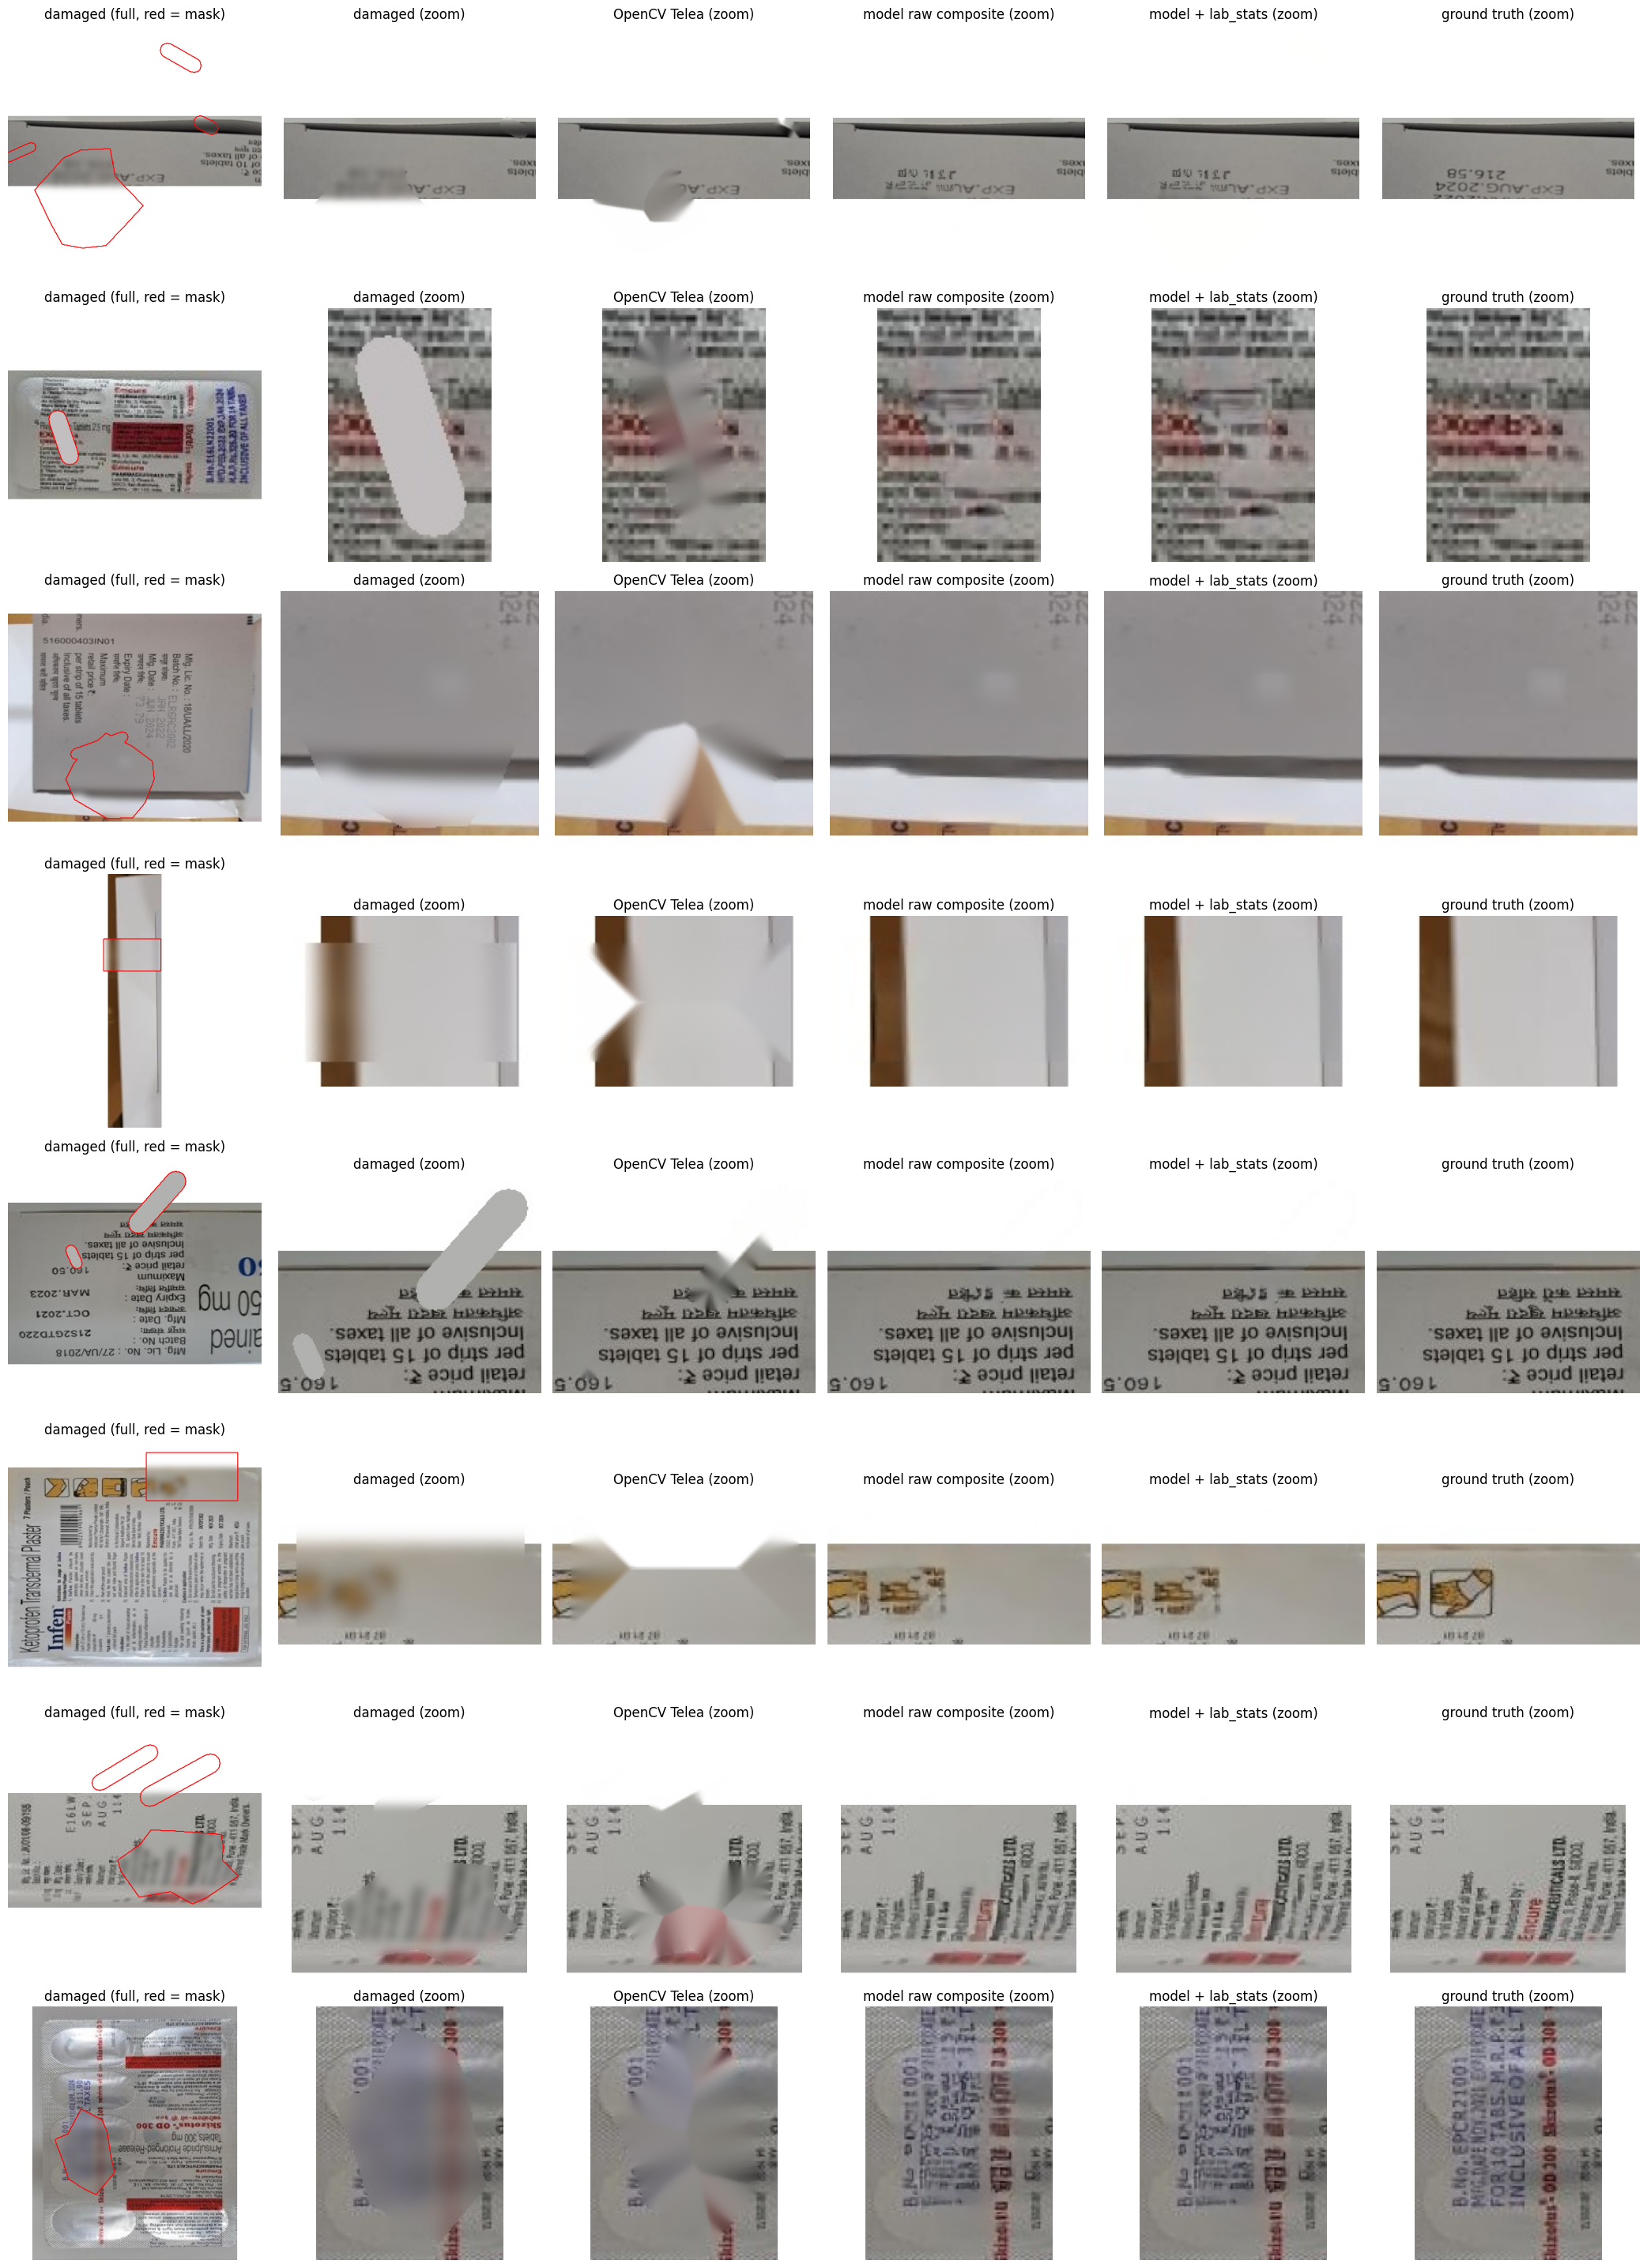

In [21]:
# Cell 15: qualitative comparison with zoom on the damaged region
if vis_cache:
    n = len(vis_cache)
    fig, ax = plt.subplots(n, 6, figsize=(21, 3.6 * n))
    ax = np.atleast_2d(ax)
    for r, (clean_i, known_i, mm, pred_i) in enumerate(vis_cache):
        ys, xs = np.nonzero(mm)
        pad = 12
        y0, y1 = max(ys.min() - pad, 0), min(ys.max() + pad, mm.shape[0])
        x0, x1 = max(xs.min() - pad, 0), min(xs.max() + pad, mm.shape[1])
        crop = lambda a: a[y0:y1, x0:x1]
        panels = [("damaged", known_i), ("OpenCV Telea", telea_baseline(known_i, mm)),
                  ("model raw composite", composite(pred_i, known_i, mm)),
                  (f"model + {best_h}", HARMONIZERS[best_h](pred_i, known_i, mm)), ("ground truth", clean_i)]
        ax[r, 0].imshow(known_i); ax[r, 0].contour(mm, levels=[0.5], colors="r", linewidths=0.8)
        ax[r, 0].set_title("damaged (full, red = mask)")
        for j, (title, im) in enumerate(panels, start=1):
            ax[r, j].imshow(np.clip(crop(im), 0, 1)); ax[r, j].set_title(title + " (zoom)")
    for a in ax.ravel(): a.axis("off")
    plt.tight_layout(); plt.savefig(OUT_DIR / "test_comparison_v2.png", dpi=110); plt.show()

In [26]:
# 

# Cell 16: Fast OCR evaluation (time-limited)

import os
import sys
import shutil
import subprocess
import time
import numpy as np
import cv2

def levenshtein(a, b):
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1,
                           prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]

# Install OCR dependencies if necessary
try:
    if shutil.which("tesseract") is None:
        subprocess.run(
            ["apt-get", "update", "-qq"],
            check=True, timeout=120,
            stdout=subprocess.DEVNULL,
            stderr=subprocess.DEVNULL
        )
        subprocess.run(
            ["apt-get", "install", "-y", "-qq", "tesseract-ocr"],
            check=True, timeout=120,
            stdout=subprocess.DEVNULL,
            stderr=subprocess.DEVNULL
        )

    try:
        import pytesseract
    except ImportError:
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "-q", "pytesseract"],
            check=True, timeout=120
        )
        import pytesseract

    pytesseract.get_tesseract_version()
    ocr = pytesseract
    print("Tesseract ready.")

except Exception as e:
    ocr = None
    print("OCR setup failed:", str(e))

if ocr is not None:
    norm_txt = lambda s: " ".join(s.split()).lower()

    def read_text(a):
        img = (np.clip(a, 0, 1) * 255).astype(np.uint8)
        img = cv2.resize(
            img, None, fx=2, fy=2,
            interpolation=cv2.INTER_CUBIC
        )
        return norm_txt(
            ocr.image_to_string(img, config="--psm 6")
        )

    cer = {
        "damaged_input": [],
        "opencv_telea": [],
        f"model+{best_h}": []
    }

    # Limit the evaluation to 10 images to conserve time.
    n_ocr = min(200, len(test_ds))
    ocr_loader = DataLoader(
        Subset(test_ds, list(range(n_ocr))),
        batch_size=1,
        num_workers=0
    )

    start_time = time.time()
    time_limit = min(15 * 60, max(0, (hours_left() - 0.1) * 3600))

    for batch_idx, (c, d, m) in enumerate(ocr_loader):
        if time.time() - start_time > time_limit:
            print("Time limit reached; stopping OCR evaluation.")
            break

        try:
            with torch.no_grad():
                _, raw = ddim_sample(
                    eval_net, d.to(device), m.to(device),
                    steps=CFG["ddim_steps"], seed=0
                )

            for i in range(c.shape[0]):
                clean_i = to_np((c[i] + 1) / 2)
                known_i = to_np((d[i] + 1) / 2)
                pred_i = to_np(raw[i])
                mm = m[i, 0].cpu().numpy() > 0.5

                ref = read_text(clean_i)
                if len(ref) < 5:
                    continue

                images = [
                    ("damaged_input", known_i),
                    ("opencv_telea", telea_baseline(known_i, mm)),
                    (f"model+{best_h}",
                     HARMONIZERS[best_h](pred_i, known_i, mm))
                ]

                for name, img in images:
                    if time.time() - start_time > time_limit:
                        break
                    text = read_text(img)
                    cer[name].append(
                        levenshtein(text, ref) / max(len(ref), 1)
                    )

            print(
                f"OCR image {batch_idx + 1}/{n_ocr} | "
                f"elapsed {((time.time() - start_time) / 60):.1f} min"
            )

        except Exception as e:
            print(f"Image {batch_idx + 1} failed: {e}")

    print("\nOCR character error rate vs. OCR of clean images")
    for name, values in cer.items():
        if values:
            print(
                f"{name:24s} CER {np.mean(values) * 100:6.2f}% "
                f"(n={len(values)})"
            )
        else:
            print(f"{name:24s} No results")

    print(f"\nOCR evaluation time: {(time.time() - start_time) / 60:.1f} min")
# Cell 16 (optional): OCR character error rate - does the reconstructed text read correctly?
# def levenshtein(a, b):
#     prev = list(range(len(b) + 1))
#     for i, ca in enumerate(a, 1):
#         cur = [i]
#         for j, cb in enumerate(b, 1):
#             cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
#         prev = cur
#     return prev[-1]

# def ensure_tesseract():
#     if shutil.which("tesseract") is None:
#         try:
#             subprocess.run("apt-get -qq update && apt-get -qq install -y tesseract-ocr", shell=True, timeout=300,
#                            stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
#         except Exception:
#             pass
#     try:
#         import pytesseract  # noqa: F401
#     except ImportError:
#         subprocess.run("pip -q install pytesseract", shell=True, timeout=300,
#                        stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
#     try:
#         import pytesseract
#         pytesseract.get_tesseract_version()
#         return pytesseract
#     except Exception:
#         return None

# ocr = ensure_tesseract() if (CFG["run_ocr_eval"] and hours_left() > 0.5) else None
# if ocr is None:
#     print("OCR evaluation skipped (tesseract unavailable, disabled, or no time left).")
# else:
#     norm_txt = lambda s: " ".join(s.split()).lower()
#     read = lambda a: norm_txt(ocr.image_to_string(cv2.resize((np.clip(a, 0, 1) * 255).astype(np.uint8), None, fx=2, fy=2,
#                                                              interpolation=cv2.INTER_CUBIC), config="--psm 6"))
#     cer = {"damaged_input": [], "opencv_telea": [], f"model+{best_h}": []}
#     ocr_loader = DataLoader(Subset(test_ds, list(range(min(CFG["ocr_eval_images"], len(test_ds))))),
#                             batch_size=CFG["eval_batch_size"], num_workers=CFG["num_workers"])
#     for c, d, m in ocr_loader:
#         if hours_left() < 0.2:
#             break
#         _, raw = ddim_sample(eval_net, d.to(device), m.to(device), steps=CFG["ddim_steps"], seed=0)
#         for i in range(c.shape[0]):
#             clean_i, known_i, pred_i = to_np((c[i] + 1) / 2), to_np((d[i] + 1) / 2), to_np(raw[i])
#             mm = m[i, 0].numpy() > 0.5
#             ref = read(clean_i)
#             if len(ref) < 5:
#                 continue
#             for k, im in [("damaged_input", known_i), ("opencv_telea", telea_baseline(known_i, mm)),
#                           (f"model+{best_h}", HARMONIZERS[best_h](pred_i, known_i, mm))]:
#                 cer[k].append(levenshtein(read(im), ref) / len(ref))
#     print("OCR character error rate vs OCR of the clean label (lower is better):")
#     for k, v in cer.items():
#         if v:
#             print(f"  {k:24s} CER {np.mean(v)*100:6.2f}%  (n={len(v)})")

Tesseract ready.
OCR image 1/200 | elapsed 0.1 min
OCR image 2/200 | elapsed 0.1 min
OCR image 3/200 | elapsed 0.2 min
OCR image 4/200 | elapsed 0.3 min
OCR image 5/200 | elapsed 0.4 min
OCR image 6/200 | elapsed 0.5 min
OCR image 7/200 | elapsed 0.5 min
OCR image 8/200 | elapsed 0.6 min
OCR image 9/200 | elapsed 0.7 min
OCR image 10/200 | elapsed 0.8 min
OCR image 11/200 | elapsed 0.9 min
OCR image 12/200 | elapsed 1.0 min
OCR image 13/200 | elapsed 1.0 min
OCR image 14/200 | elapsed 1.1 min
OCR image 15/200 | elapsed 1.2 min
OCR image 16/200 | elapsed 1.3 min
OCR image 17/200 | elapsed 1.4 min
OCR image 18/200 | elapsed 1.5 min
OCR image 19/200 | elapsed 1.6 min
OCR image 20/200 | elapsed 1.7 min
OCR image 21/200 | elapsed 1.7 min
OCR image 22/200 | elapsed 1.8 min
OCR image 23/200 | elapsed 1.9 min
OCR image 24/200 | elapsed 2.0 min
OCR image 25/200 | elapsed 2.1 min
OCR image 26/200 | elapsed 2.3 min
OCR image 27/200 | elapsed 2.4 min
OCR image 28/200 | elapsed 2.5 min
OCR image 29

In [27]:
# Cell 17: efficiency benchmark and output summary
c, d, m = next(iter(DataLoader(test_ds, batch_size=1)))
d, m = d.to(device), m.to(device)
res = ddim_sample(eval_net, d, m, steps=CFG["ddim_steps"])  # warm-up
if device.type == "cuda": torch.cuda.synchronize()
t0 = time.time()
res = ddim_sample(eval_net, d, m, steps=CFG["ddim_steps"])
if device.type == "cuda": torch.cuda.synchronize()
lat = time.time() - t0
t0 = time.time(); _h = HARMONIZERS[best_h](to_np(res[1][0]), to_np((d[0] + 1) / 2), m[0, 0].cpu().numpy() > 0.5)
lat_h = time.time() - t0

print("--- Efficiency ---")
print(f"Parameters            : {total_params:,}")
print(f"Model size (fp32)     : {total_params * 4 / 2**20:.1f} MB")
print(f"Latency per label     : {lat:.3f} s (DDIM-{CFG['ddim_steps']}, {CFG['image_size']}x{CFG['image_size']})")
print(f"Harmoniser '{best_h}' : {lat_h*1000:.1f} ms")
print(f"Training time         : {state['train_seconds']/3600:.2f} h over {state['epoch']} epochs")
print(f"Notebook wall time    : {hours_used():.2f} h")
print("\nFiles in", OUT_DIR)
for p in sorted(OUT_DIR.iterdir()):
    print(f"  {p.name:32s} {p.stat().st_size/2**20:8.2f} MB")

--- Efficiency ---
Parameters            : 22,293,571
Model size (fp32)     : 85.0 MB
Latency per label     : 3.834 s (DDIM-25, 416x416)
Harmoniser 'lab_stats' : 15.1 ms
Training time         : 8.50 h over 10 epochs
Notebook wall time    : 11.51 h

Files in /kaggle/working
  .virtual_documents                   0.00 MB
  best_ema.pth                        85.14 MB
  data_check.png                       0.17 MB
  dataset_split_v2.csv                 1.37 MB
  last_checkpoint.pth                340.63 MB
  selected_harmonizer.txt              0.00 MB
  test_comparison_v2.png               2.03 MB
  test_metrics_v2.csv                  0.00 MB
  train_history.json                   0.00 MB
  training_curves.png                  0.06 MB


Displaying cached reconstruction results.


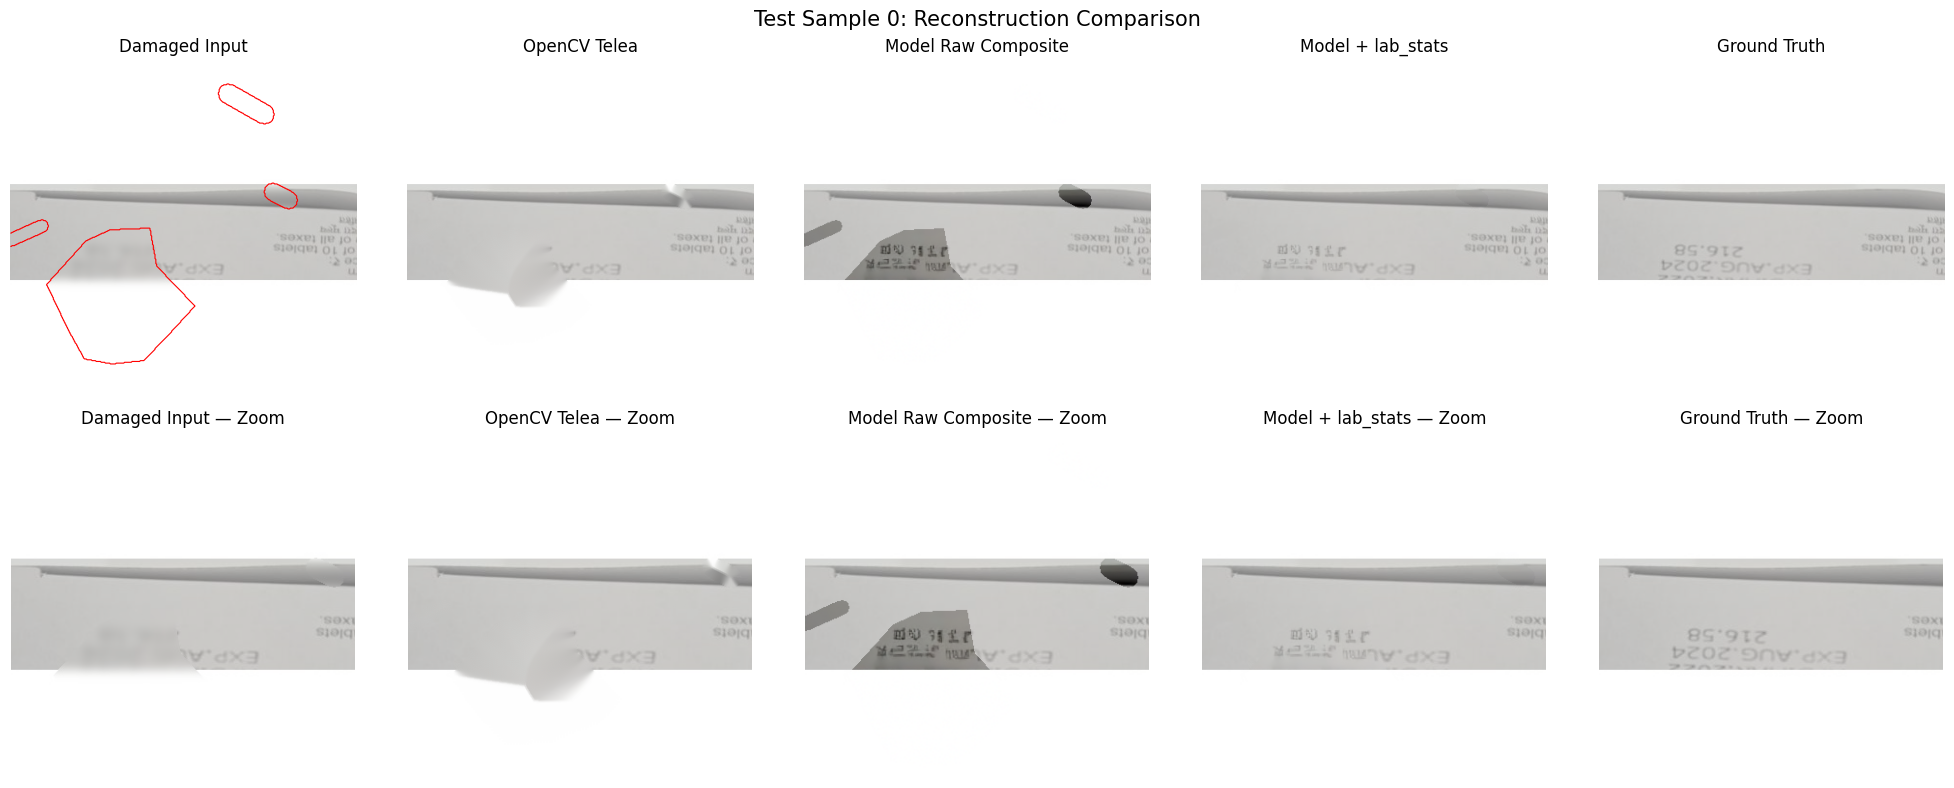

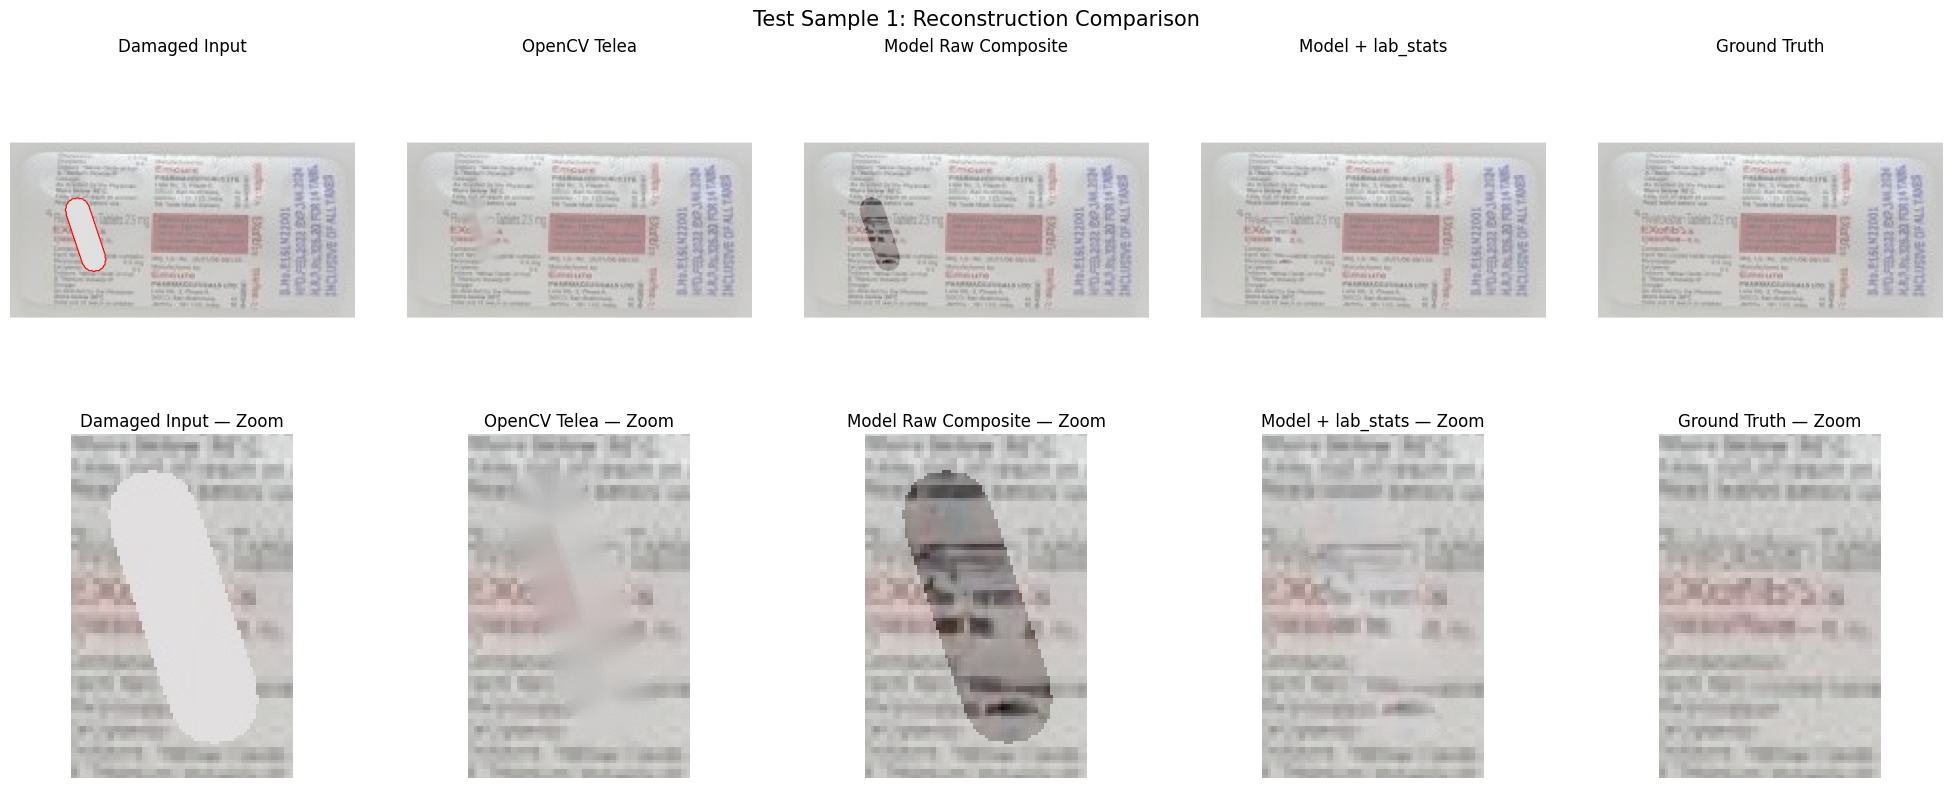

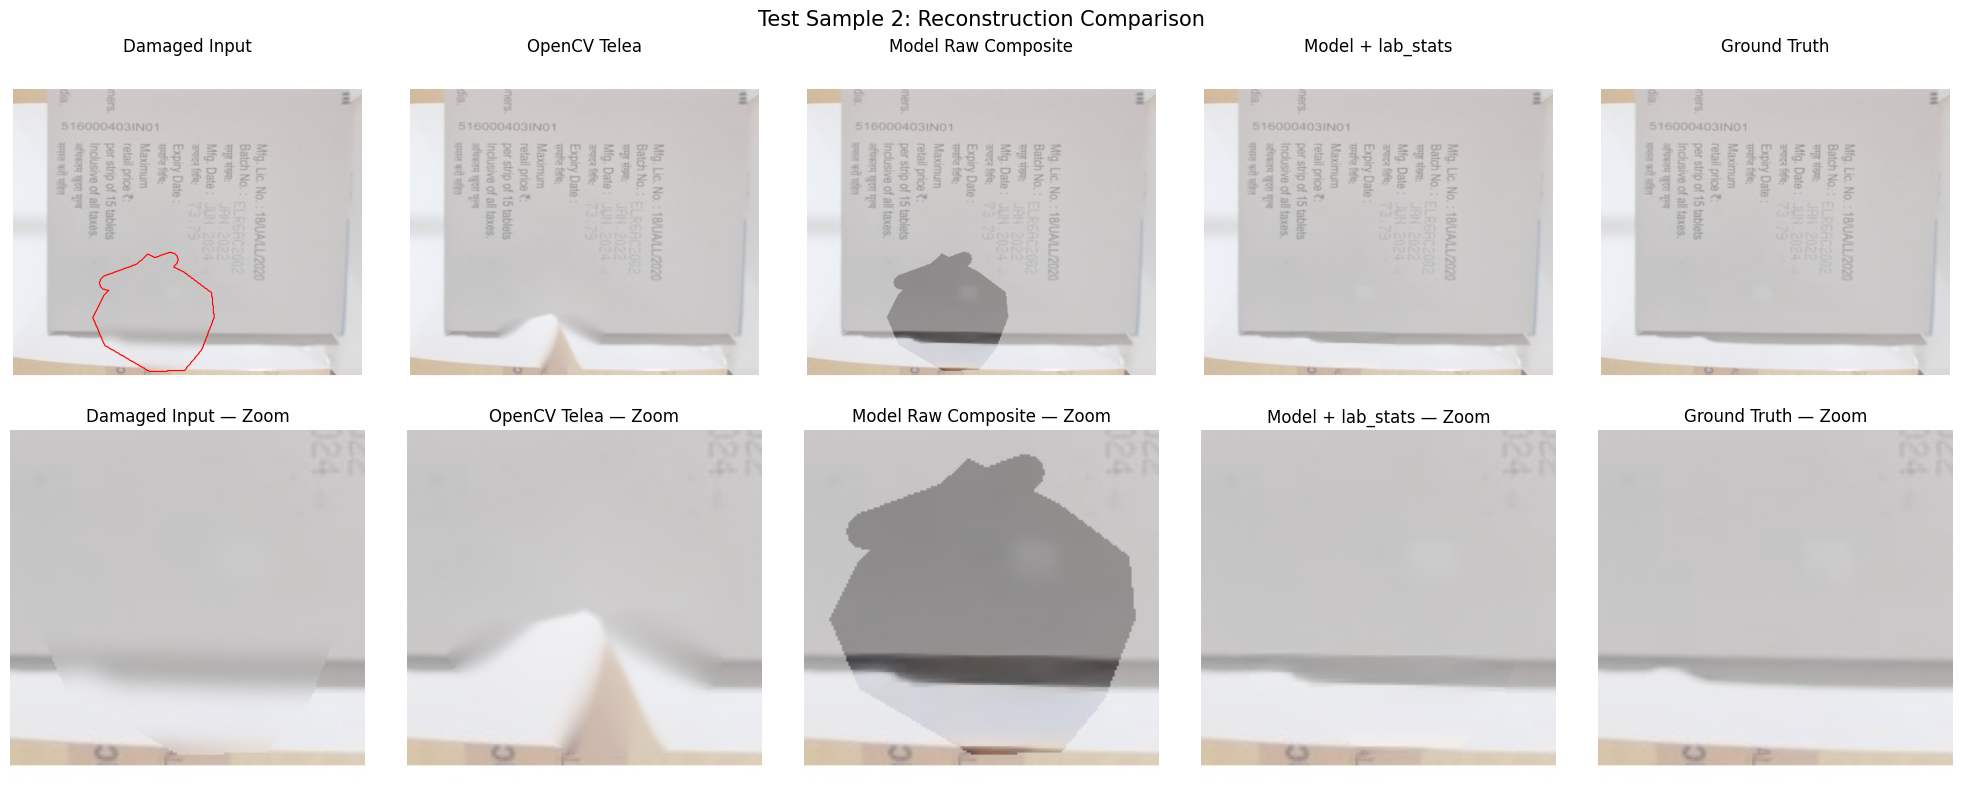

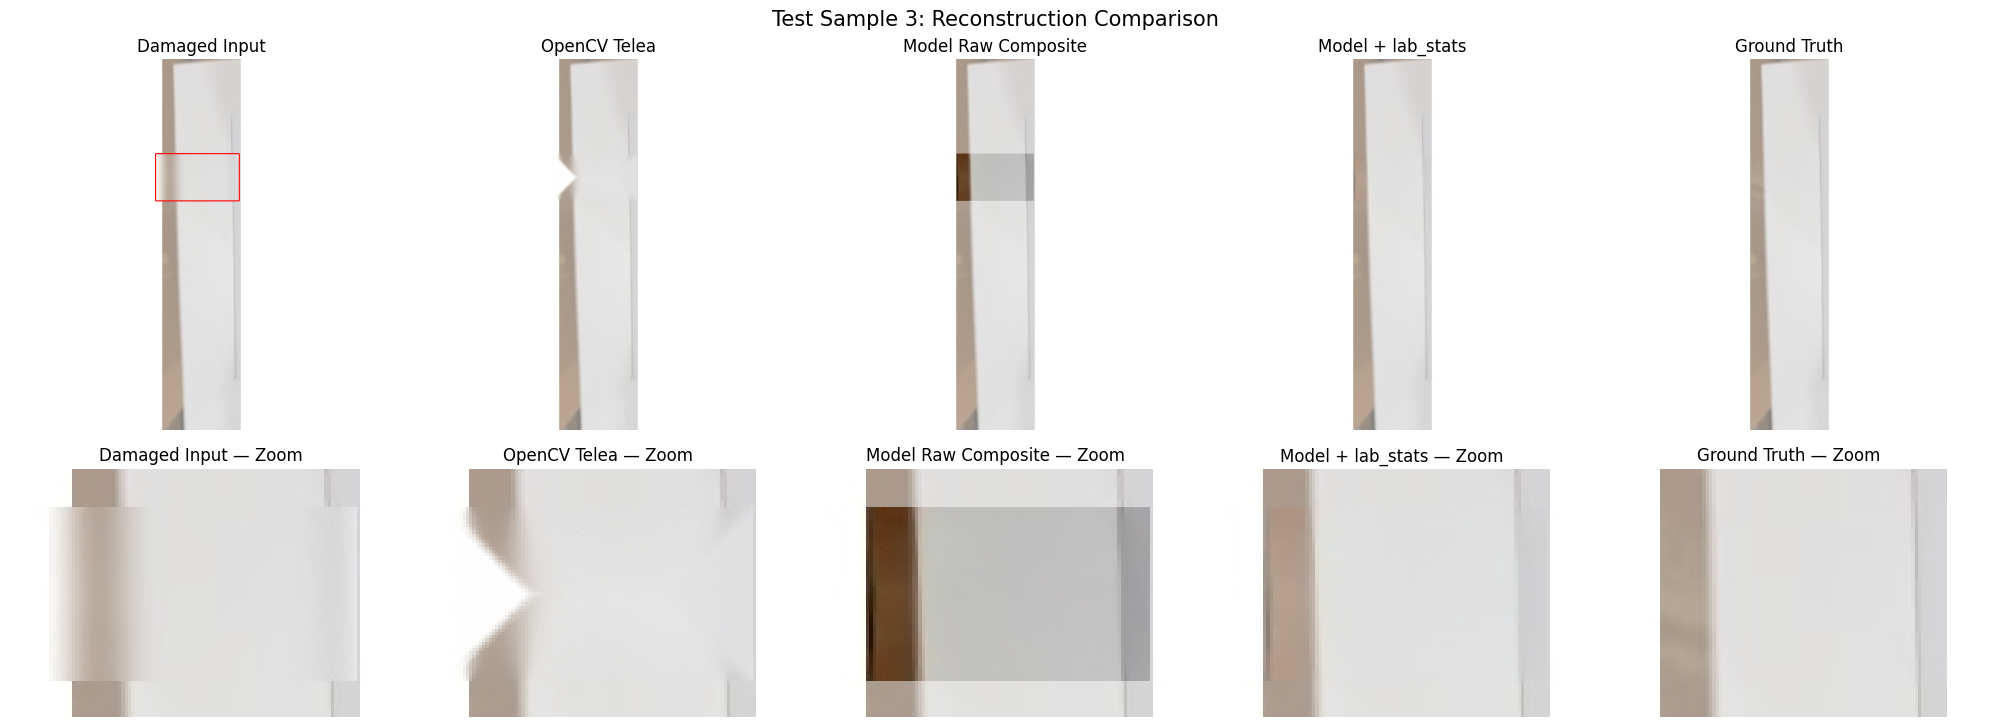

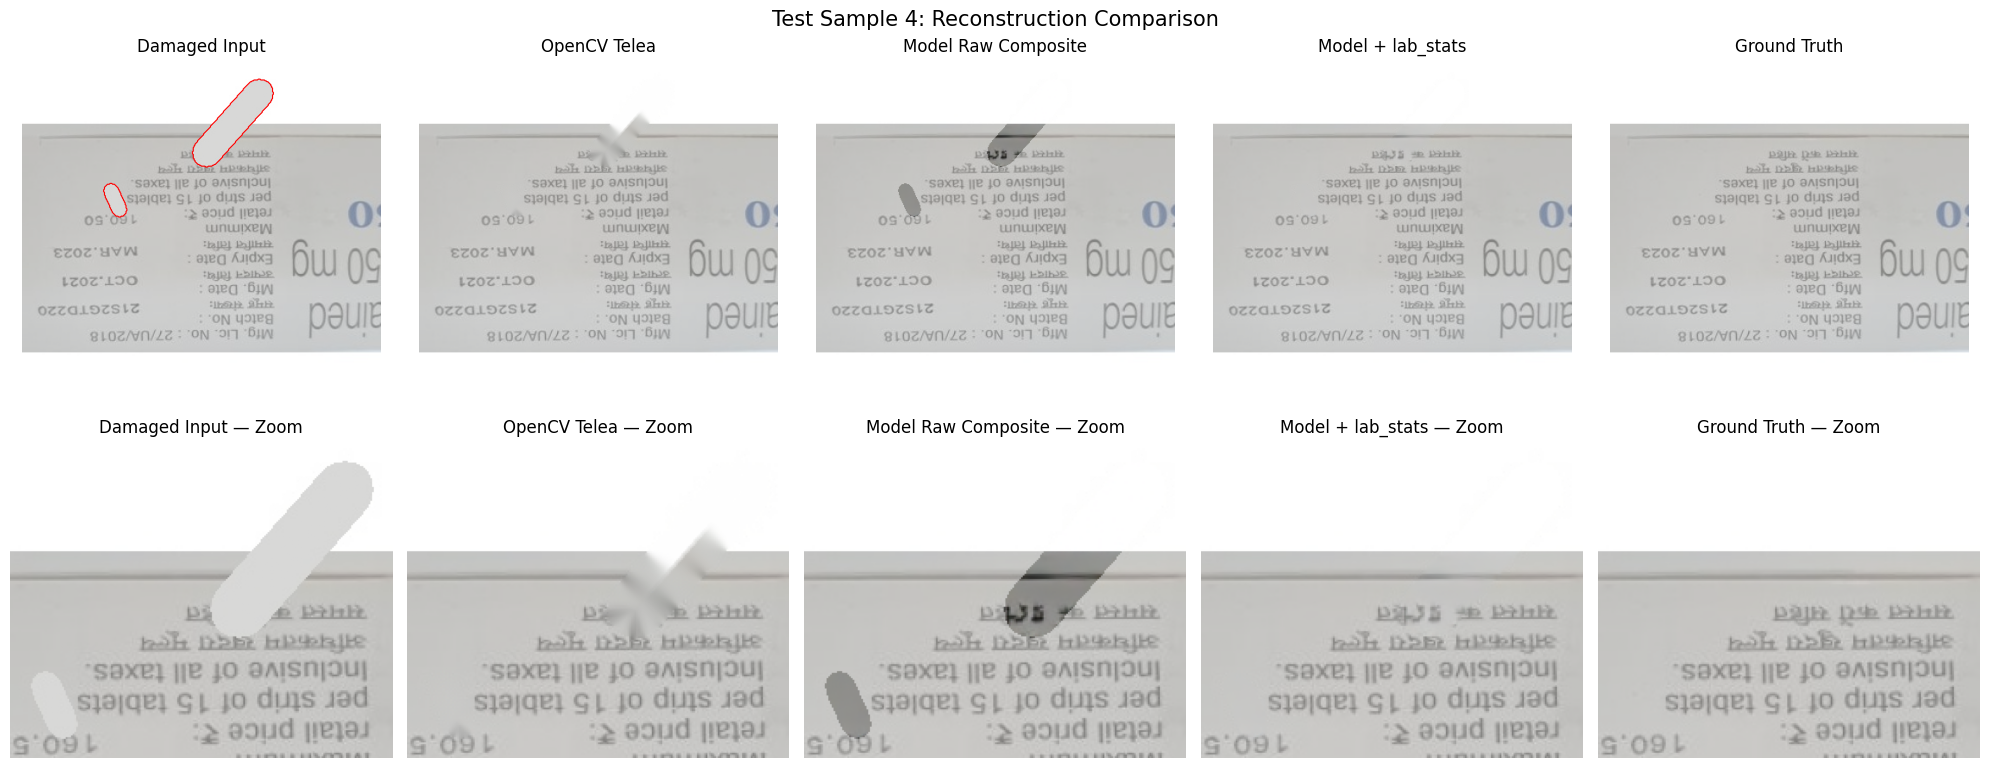

Visualization completed.


<Figure size 640x480 with 0 Axes>

In [31]:
# Final Cell: Test Image Visualization and Reconstruction Comparison

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader, Subset

N_VIS = 5

def as_image(x, normalize=False):
    """Convert a tensor or NumPy array to an HxWxC image."""
    if torch.is_tensor(x):
        x = x.detach().cpu().float().numpy()

    x = np.asarray(x)

    # CHW -> HWC
    if x.ndim == 3 and x.shape[0] in (1, 3, 4):
        x = np.transpose(x, (1, 2, 0))

    # Remove singleton channel for masks
    if x.ndim == 3 and x.shape[-1] == 1:
        x = x[..., 0]

    x = x.astype(np.float32)

    # Convert normalized [-1, 1] images to [0, 1] if requested
    if normalize:
        x = (x + 1.0) / 2.0

    return np.clip(x, 0, 1)


def visualize_reconstruction(clean, damaged, mask, prediction, idx):
    clean = as_image(clean, normalize=True)
    damaged = as_image(damaged, normalize=True)
    prediction = as_image(prediction)

    mask = as_image(mask)
    if mask.ndim == 3:
        mask = mask[..., 0]
    mask = mask > 0.5

    # Reconstruction methods
    telea = telea_baseline(damaged, mask)
    raw_composite = composite(prediction, damaged, mask)
    harmonized = HARMONIZERS[best_h](prediction, damaged, mask)

    # Find the damaged region
    ys, xs = np.nonzero(mask)

    if len(ys):
        pad = 12
        y0 = max(0, ys.min() - pad)
        y1 = min(mask.shape[0], ys.max() + pad)
        x0 = max(0, xs.min() - pad)
        x1 = min(mask.shape[1], xs.max() + pad)
    else:
        y0, y1 = 0, mask.shape[0]
        x0, x1 = 0, mask.shape[1]

    panels = [
        ("Damaged Input", damaged),
        ("OpenCV Telea", telea),
        ("Model Raw Composite", raw_composite),
        (f"Model + {best_h}", harmonized),
        ("Ground Truth", clean),
    ]

    fig, axes = plt.subplots(2, 5, figsize=(20, 8))

    for j, (title, img) in enumerate(panels):
        axes[0, j].imshow(img)
        axes[0, j].set_title(title)
        axes[0, j].axis("off")

        axes[1, j].imshow(img[y0:y1, x0:x1])
        axes[1, j].set_title(f"{title} — Zoom")
        axes[1, j].axis("off")

    axes[0, 0].contour(
        mask, levels=[0.5], colors="red", linewidths=0.8
    )

    fig.suptitle(
        f"Test Sample {idx}: Reconstruction Comparison",
        fontsize=15
    )
    plt.tight_layout()
    plt.show()


# Prefer cached results to avoid expensive additional inference.
if "vis_cache" in globals() and len(vis_cache) > 0:

    print("Displaying cached reconstruction results.")

    for idx, (clean, damaged, mask, prediction) in enumerate(
        vis_cache[:N_VIS]
    ):
        visualize_reconstruction(
            clean, damaged, mask, prediction, idx
        )

else:
    print("No cached results. Generating up to 5 examples.")

    n_vis = min(N_VIS, len(test_ds))

    vis_loader = DataLoader(
        Subset(test_ds, list(range(n_vis))),
        batch_size=1,
        shuffle=False,
        num_workers=0
    )

    eval_net.eval()

    with torch.no_grad():
        for idx, (clean, damaged, mask) in enumerate(vis_loader):

            _, prediction = ddim_sample(
                eval_net,
                damaged.to(device),
                mask.to(device),
                steps=CFG["ddim_steps"],
                seed=idx
            )

            visualize_reconstruction(
                clean[0],
                damaged[0],
                mask[0, 0].cpu().numpy(),
                prediction[0],
                idx
            )

print("Visualization completed.")
plt.savefig("visual.png", dpi=150, bbox_inches="tight")
plt.show()

In [30]:
plt.savefig("visual.png", dpi=150, bbox_inches="tight")
plt.show()

<Figure size 640x480 with 0 Axes>